# Candle Pavio — estratégia final

Execute as células em ordem e selecione as quatro planilhas quando solicitado. Funciona no Google Colab e no VS Code com Python local.


## Bloco 0 — Configuração

Parâmetros, janelas, seleção de ativos, custos e métricas.


In [2]:
# =============================================================================
# BLOCO 0 — Bibliotecas e configuração central
# -----------------------------------------------------------------------------
# Esta é a ÚNICA célula com os números da estratégia. Para mudar parâmetros,
# janelas, filtros ou custos, mude aqui e rode o notebook de novo a partir daqui.
# Os códigos [Dxx] apontam para o "registro-de-decisoes.md" do projeto.
# =============================================================================

# ---- Bibliotecas ------------------------------------------------------------
import itertools                  # gera a grade de combinações de parâmetros
from pathlib import Path          # monta caminhos de pastas e arquivos

import numpy as np                # contas vetorizadas
import pandas as pd               # tabelas (DataFrames)
import matplotlib                 # gráficos (Bloco 13)
import matplotlib.pyplot as plt
import scipy                      # estatística (Bloco 11)
import statsmodels                # teste t com erros-padrão agrupados (Bloco 11)

pd.set_option("display.max_columns", 40)   # mostra mais colunas nos prints
pd.set_option("display.width", 200)


# Configuração final da estratégia
VERSAO = 3


# =============================================================================
# 1. ARQUIVOS E PASTAS
# =============================================================================
# Os arquivos serão escolhidos pelo usuário ao executar o Bloco 1.
# A pasta temporária é criada automaticamente, sem configuração manual.
import tempfile
import importlib.util
ORIGEM_DOS_DADOS = "upload"
PASTA_DADOS = Path(tempfile.mkdtemp(prefix="candle_pavio_dados_"))
EM_COLAB = importlib.util.find_spec("google.colab") is not None if importlib.util.find_spec("google") is not None else False
PASTA_GERAL = Path("/content/resultados") if EM_COLAB else Path.cwd() / "resultados"

# Cópia rápida dos Excels já lidos (o Bloco 1 lê os .xlsx uma vez só e relê se eles mudarem).
# Fica na pasta geral para reaproveitar a leitura.
ARQUIVO_CACHE = PASTA_GERAL / "cache_dados_brutos.pkl"
# Pasta de resultados desta estratégia.
PASTA_RESULTADOS = PASTA_GERAL / "candle_pavio_final"
# Cópia do CDI baixado do Banco Central (o Bloco 10 usa se o site estiver fora do ar).
ARQUIVO_CDI = PASTA_RESULTADOS / "cdi_banco_central.csv"

# A Economatica escreve o nome da variável na 1ª linha do cabeçalho de cada
# coluna. O Bloco 1 usa este dicionário para descobrir o que há em cada aba,
# sem depender do nome do arquivo nem do nome da aba.
#   texto na 1ª linha do cabeçalho  →  nome da coluna no nosso código
VARIAVEIS_ECONOMATICA = {
    "Abertura":   "abertura",
    "Máximo":     "maxima",
    "Mínimo":     "minima",
    "Fechamento": "fechamento",
    "Media":      "volume_medio_1m",   # média móvel de 1 mês do volume [D11]
}


# =============================================================================
# 2. PERÍODO E LIMPEZA DOS DADOS
# =============================================================================
DATA_INICIO = "2015-01-01"
DATA_FIM = "2025-12-31"                  # [D02] máx/mín/volume vão até 2026

# Ativos removidos à mão, com o motivo (vai para o relatório de qualidade).
ATIVOS_EXCLUIDOS = {
    "SEM_NOME": "Coluna sem nome de ativo no cabeçalho, não identificável [D03]",
}

# O Ibovespa veio nos Excels como se fosse mais uma coluna de ativo. O Bloco 2
# separa essa coluna como referência (benchmark) e a tira do universo de ações,
# senão ele passaria em todos os filtros como a "ação" mais líquida. [D37]
NOME_IBOVESPA_NA_BASE = "Ibovespa"

TOLERANCIA_OHLC = 0.0001                 # [D04] 0,01% de folga para arredondamento
MAX_FRACAO_DIAS_INCONSISTENTES = 0.01    # [D04] acima de 1% dos dias, exclui o ativo
LIMITE_GAP_EVENTO = 0.25                 # [D08] |gap| > 25% não gera sinal (None desliga)


# =============================================================================
# 3. ESTRATÉGIA (metodologia v8, seções 3 e 4)
# =============================================================================
VERSOES = ["compra", "venda"]            # avaliadas sempre separadamente

THETAS = [0.10, 0.20, 0.30]              # corpo máximo / amplitude do candle t−1
GAPS_MINIMOS = [0.005, 0.010, 0.015, 0.020]
STOPS = [0.01, 0.02, 0.03]

PERIODO_MM = 200                         # filtro de tendência fixo: MM200 [D09]

# Grade de combinações: todas as triplas (θ, g, s).
combinacoes = list(itertools.product(THETAS, GAPS_MINIMOS, STOPS))
GRADE = pd.DataFrame(combinacoes, columns=["theta", "gap_minimo", "stop"])
GRADE.insert(0, "id_combinacao", range(1, len(GRADE) + 1))


# =============================================================================
# 4. JANELAS WALK-FORWARD (metodologia v8, Tabela 4)
# =============================================================================
JANELAS = pd.DataFrame(
    [
        # janela  treino (início, fim)        validação (início, fim)     teste (início, fim)
        (1, "2015-01-01", "2018-12-31", "2019-01-01", "2019-12-31", "2020-01-01", "2021-12-31"),
        (2, "2017-01-01", "2020-12-31", "2021-01-01", "2021-12-31", "2022-01-01", "2023-12-31"),
        (3, "2019-01-01", "2022-12-31", "2023-01-01", "2023-12-31", "2024-01-01", "2025-12-31"),
    ],
    columns=["janela", "treino_inicio", "treino_fim", "validacao_inicio",
             "validacao_fim", "teste_inicio", "teste_fim"],
)
for coluna in JANELAS.columns.drop("janela"):
    JANELAS[coluna] = pd.to_datetime(JANELAS[coluna])
JANELAS = JANELAS.set_index("janela")


# =============================================================================
# 5. SELEÇÃO DE AÇÕES (metodologia v8, Tabela 5)
# =============================================================================
VOLUME_MINIMO = 5_000_000                # R$ por dia (critério 1)
VOLUME_EM_MILHARES = True                # [D11] a Economatica exportou em R$ mil
PRESENCA_MINIMA = 0.90                   # [D12] fração dos pregões do treino (critério 2)
PRECO_MINIMO = 5.0                       # R$ (critério 3): a R$ 5, 1 centavo = 0,2% do preço [D45]
FILTRO_PRECO_ATIVO = True                # [D14] False desliga o critério 3
# [D45] Qual preço o filtro usa. O preço ajustado da Economatica não é o preço de tela
# (a Petrobras de jan/2017 aparece a R$ 3,73, mas era negociada a R$ 16).
# o filtro usa o preço real estimado no Bloco 3 a partir do centavo.
PRECO_DO_FILTRO = "real_estimado"
PREGOES_PARA_ESTIMAR_CENTAVO = 120       # [D45] janela usada para achar o "centavo ajustado"
SINAIS_MINIMOS_POR_VERSAO = 20           # critério 4: mínimo de compras E de vendas
THETA_REFERENCIA_SELECAO = 0.30          # critério 4: θ usado na contagem
GAP_REFERENCIA_SELECAO = 0.005           # critério 4: g usado na contagem
NUMERO_MAXIMO_DE_ACOES = 30              # critério 6: as 30 mais líquidas


# =============================================================================
# 6. OTIMIZAÇÃO E VALIDAÇÃO (metodologia v8, seção 5.4)
# =============================================================================
MIN_OPERACOES_TREINO = 100               # combinação elegível no treino
N_CANDIDATAS = 5                         # [D20] melhores do treino que vão à validação
MIN_OPERACOES_VALIDACAO = 30             # candidata elegível na validação
# [D46] Como escolher entre as combinações, no treino e na validação:
# Seleção pela estatística t.
CRITERIO_ESCOLHA = "t"
# [D43] Só passa para o teste uma combinação com retorno médio líquido POSITIVO na validação.
# Se nenhuma for positiva, a versão não opera naquela janela e o capital fica no CDI.
# Não utilizado na configuração final.
EXIGIR_RETORNO_POSITIVO_VALIDACAO = False
# [D47] Só vai para a validação uma combinação com retorno médio líquido POSITIVO no treino.
# Não utilizado na configuração final.
EXIGIR_RETORNO_POSITIVO_TREINO = False


# =============================================================================
# 7. EXECUÇÃO, CUSTOS E CARTEIRA (metodologia v8, seção 6)
# =============================================================================
CUSTO_IDA_E_VOLTA = 0.0010               # 0,10% por operação
CUSTOS_SENSIBILIDADE = [0.0005, 0.0010, 0.0015, 0.0020]   # [D35]
K_FIXO = 30                              # [D17] cada sinal usa 1/K do capital (None = nº de ações)
REMUNERAR_CAIXA_CDI = True        # [D42] capital parado rende CDI

# Carteiras analisadas: cada uma junta as operações das versões listadas. A "integrada"
# (compra + venda na mesma carteira) é o resultado principal; compra e venda separadas
# mostram de onde vem o resultado. [D25]
CARTEIRAS = {"integrada": ["compra", "venda"], "compra": ["compra"], "venda": ["venda"]}


# =============================================================================
# 8. MÉTRICAS, ESTATÍSTICA E REFERÊNCIAS (metodologia v8, seções 7 e 8)
# =============================================================================
PREGOES_POR_ANO = 252                    # [D26] anualização
CODIGO_SGS_CDI = 12                      # [D28] CDI diário no Banco Central
FONTE_IBOVESPA = "economatica"           # [D37] coluna NOME_IBOVESPA_NA_BASE dos próprios Excels
BOOTSTRAP_N = 10_000                     # [D32] número de reamostragens
BOOTSTRAP_TAMANHO_BLOCO = 10             # [D32] pregões por bloco
NIVEL_CONFIANCA = 0.95                   # intervalos de confiança
SEMENTE = 42                             # [D32] semente aleatória (reprodutibilidade)
DEFASAGENS_NEWEY_WEST = 5                # [D48] beta e alfa (Bloco 15): aceita dias seguidos parecidos
# [D49] Faixas de gap do fato de 2015–2019 (Bloco 15): de baixa, perto de zero e de alta
FAIXAS_DE_GAP = [-1.0, -0.02, -0.01, -0.005, 0.005, 0.01, 0.02, 1.0]
PERIODO_EVENTO_RJ_OPA = "treino_ate_teste"   # [D36] "treino_ate_teste", "so_teste" ou "so_treino"

# [D36] Ações em recuperação judicial (RJ) ou OPA, retiradas numa das análises do Bloco 12.
# Datas aproximadas pelo mês do fato relevante. Revisar se a seleção de ações mudar.
LISTA_RJ_OPA = {
    # ativo:           (início,       fim,          evento)
    "Oi ON":           ("2016-06-20", "2025-12-31", "RJ (1ª de jun/2016 a dez/2022; 2ª desde mar/2023)"),
    "Americanas ON":   ("2023-01-19", "2025-12-31", "RJ pedida em jan/2023"),
    "CPFL Energia ON": ("2017-01-01", "2017-12-31", "OPA por alienação de controle à State Grid"),
    "Gol PN":          ("2024-01-25", "2025-06-30", "Chapter 11 nos EUA (equivalente à RJ); só é "
                                                    "selecionada com o filtro de preço desligado"),
}
# [D44] Número histórico de configurações avaliadas no teste, preservado para a correção estatística.
VERSOES_OLHADAS_NO_TESTE = 3


# =============================================================================
# 9. VERIFICAÇÕES DE SANIDADE DA CONFIGURAÇÃO
# =============================================================================
assert ORIGEM_DOS_DADOS in ("drive", "upload"), "ORIGEM_DOS_DADOS deve ser 'drive' ou 'upload'"

# Grade: 3 × 4 × 3 = 36 combinações, sem repetição
assert len(GRADE) == len(THETAS) * len(GAPS_MINIMOS) * len(STOPS) == 36
assert not GRADE.duplicated(subset=["theta", "gap_minimo", "stop"]).any()
assert all(0 < valor < 1 for valor in THETAS + GAPS_MINIMOS + STOPS)

# Janelas: dentro de cada uma, treino < validação < teste, sem sobreposição
for janela, datas in JANELAS.iterrows():
    assert datas["treino_inicio"] < datas["treino_fim"] < datas["validacao_inicio"], f"Janela {janela}"
    assert datas["validacao_inicio"] < datas["validacao_fim"] < datas["teste_inicio"], f"Janela {janela}"
    assert datas["teste_inicio"] < datas["teste_fim"], f"Janela {janela}"

# Testes: um começa no dia seguinte ao fim do outro (curva contínua, sem dia repetido)
for janela_atual, janela_seguinte in zip(JANELAS.index[:-1], JANELAS.index[1:]):
    fim_atual = JANELAS.loc[janela_atual, "teste_fim"]
    inicio_seguinte = JANELAS.loc[janela_seguinte, "teste_inicio"]
    assert inicio_seguinte == fim_atual + pd.Timedelta(days=1), "Testes com buraco ou sobreposição"

assert JANELAS["treino_inicio"].min() >= pd.Timestamp(DATA_INICIO)
assert JANELAS["teste_fim"].max() <= pd.Timestamp(DATA_FIM)
assert CUSTO_IDA_E_VOLTA in CUSTOS_SENSIBILIDADE
assert K_FIXO is None or K_FIXO > 0
assert PERIODO_EVENTO_RJ_OPA in ("treino_ate_teste", "so_teste", "so_treino")
assert VERSOES_OLHADAS_NO_TESTE >= 1
assert PRECO_DO_FILTRO in ("ajustado", "real_estimado")
assert CRITERIO_ESCOLHA in ("media", "t")
assert FAIXAS_DE_GAP == sorted(FAIXAS_DE_GAP)
assert all(set(versoes) <= set(VERSOES) for versoes in CARTEIRAS.values())


# =============================================================================
# 10. RESUMO (também guardado para a exportação do Bloco 14)
# =============================================================================
# Junta todas as constantes desta célula (nomes em MAIÚSCULAS e valores simples)
# num dicionário, para salvar junto com os resultados.
TIPOS_SIMPLES = (int, float, str, bool, list, dict, type(None))
CONFIGURACAO_USADA = {
    nome: valor
    for nome, valor in globals().items()
    if nome.isupper() and isinstance(valor, TIPOS_SIMPLES)
}
CONFIGURACAO_USADA["PASTA_DADOS"] = str(PASTA_DADOS)
CONFIGURACAO_USADA["PASTA_GERAL"] = str(PASTA_GERAL)
CONFIGURACAO_USADA["PASTA_RESULTADOS"] = str(PASTA_RESULTADOS)

print("=" * 72)
print("CONFIGURAÇÃO CARREGADA")
print("=" * 72)
print(f"Versões de bibliotecas: pandas {pd.__version__} | numpy {np.__version__} | "
      f"scipy {scipy.__version__} | statsmodels {statsmodels.__version__} | "
      f"matplotlib {matplotlib.__version__}")
print(f"Pasta dos dados:      {PASTA_DADOS}")
print(f"Pasta dos resultados: {PASTA_RESULTADOS}")
print(f"Período:              {DATA_INICIO} a {DATA_FIM}")
print(f"Versões:              {VERSOES}")
print(f"Grade:                {len(GRADE)} combinações por versão "
      f"({len(THETAS)} θ × {len(GAPS_MINIMOS)} g × {len(STOPS)} s), filtro MM{PERIODO_MM} fixo")
print(f"Custo:                {CUSTO_IDA_E_VOLTA:.2%} ida e volta | K = {K_FIXO}")
print(f"Configuração final:     caixa no CDI = {REMUNERAR_CAIXA_CDI} | positivo na validação = "
      f"{EXIGIR_RETORNO_POSITIVO_VALIDACAO} | positivo no treino = {EXIGIR_RETORNO_POSITIVO_TREINO} | "
      f"preço do filtro = {PRECO_DO_FILTRO} | critério = {CRITERIO_ESCOLHA}")
print(f"Carteiras:            {CARTEIRAS}")
print(f"Benchmark:            coluna '{NOME_IBOVESPA_NA_BASE}' dos Excels (fonte: {FONTE_IBOVESPA})")
print(f"Parâmetros guardados: {len(CONFIGURACAO_USADA)}")

print("\nPrimeiras combinações da grade:")
print(GRADE.head(6).to_string(index=False))

print("\nJanelas walk-forward:")
print(JANELAS.apply(lambda coluna: coluna.dt.strftime("%d/%m/%Y")).to_string())
print("\nTodas as verificações da configuração passaram.")

CONFIGURAÇÃO CARREGADA
Versões de bibliotecas: pandas 2.2.2 | numpy 1.26.4 | scipy 1.13.1 | statsmodels 0.14.2 | matplotlib 3.9.2
Pasta dos dados:      /var/folders/3k/6sq134gx0w99q_v3_2rcjwh80000gn/T/candle_pavio_dados_rmlpnng8
Pasta dos resultados: /Users/carolinayumigentil/Documents/GitHub/projeto-avantgarde-2/c-digos---projeto-final-/grupo 1/resultados/candle_pavio_final
Período:              2015-01-01 a 2025-12-31
Versões:              ['compra', 'venda']
Grade:                36 combinações por versão (3 θ × 4 g × 3 s), filtro MM200 fixo
Custo:                0.10% ida e volta | K = 30
Configuração final:     caixa no CDI = True | positivo na validação = False | positivo no treino = False | preço do filtro = real_estimado | critério = t
Carteiras:            {'integrada': ['compra', 'venda'], 'compra': ['compra'], 'venda': ['venda']}
Benchmark:            coluna 'Ibovespa' dos Excels (fonte: economatica)
Parâmetros guardados: 53

Primeiras combinações da grade:
 id_combinacao  t

## Bloco 1 — Leitura dos dados

Selecione as quatro planilhas no Colab ou no VS Code.


In [3]:
# =============================================================================
# BLOCO 1 — Leitura dos Excels da Economatica
# =============================================================================

def numerar_repetidos(nomes):
    """Acrescenta (1), (2)... a nomes que aparecem mais de uma vez.

    Ex.: ["Brisanet ON", "Vale ON", "Brisanet ON"]
      →  ["Brisanet ON (1)", "Vale ON", "Brisanet ON (2)"]
    """
    vistos = {}
    resultado = []
    for nome in nomes:
        if nomes.count(nome) > 1:
            vistos[nome] = vistos.get(nome, 0) + 1
            nome = f"{nome} ({vistos[nome]})"
        resultado.append(nome)
    return resultado


def organizar_aba(bruto):
    """Transforma uma aba crua da Economatica numa tabela larga.

    Parâmetro: bruto = aba lida sem cabeçalho (pd.read_excel com header=None).
    Retorna: (variavel, tabela), com uma linha por data e uma coluna por ativo,
             ou (None, None) se a aba não for de uma variável conhecida.
    """
    # O cabeçalho é a linha que começa com "Data" (nas abas de máx/mín há 3 linhas antes)
    linha = bruto.index[bruto[0] == "Data"][0]
    cabecalhos = bruto.iloc[linha, 1:].astype(str).tolist()

    # Cada cabeçalho tem várias linhas: a 1ª é a variável, a última é o ativo
    variavel = VARIAVEIS_ECONOMATICA.get(cabecalhos[0].split("\n")[0])
    if variavel is None:
        return None, None

    # A coluna sem nome de ativo tem uma linha a menos no cabeçalho [D03]
    linhas_completas = max(c.count("\n") for c in cabecalhos)
    nomes = [c.split("\n")[-1] if c.count("\n") == linhas_completas else "SEM_NOME"
             for c in cabecalhos]

    tabela = bruto.iloc[linha + 1:, 1:].apply(pd.to_numeric, errors="coerce")   # "-" vira NaN
    tabela.index = pd.to_datetime(bruto.iloc[linha + 1:, 0])
    tabela.index.name = "data"

    # Tira colunas sem nenhum dado ANTES de numerar repetidos: assim um ativo que
    # aparece duas vezes, mas com uma das colunas vazia, fica com o nome original
    tem_dados = tabela.notna().any().tolist()
    tabela = tabela.loc[:, tem_dados]
    tabela.columns = numerar_repetidos([n for n, tem in zip(nomes, tem_dados) if tem])
    return variavel, tabela


def carregar_dados_economatica():
    """Lê todos os .xlsx de PASTA_DADOS e devolve {variável: tabela larga}.

    Na primeira vez lê os Excels (cerca de 1 minuto) e salva uma cópia em ARQUIVO_CACHE.
    Nas próximas, carrega a cópia em segundos, desde que os Excels sejam os mesmos
    (mesmos nomes e tamanhos). Se algum Excel mudar, lê tudo de novo.
    """
    # Ignora arquivos "~$..." (cópias temporárias que o Excel cria enquanto o arquivo está aberto)
    arquivos = [a for a in sorted(PASTA_DADOS.glob("*.xlsx")) if not a.name.startswith("~$")]
    assert arquivos, f"Nenhum .xlsx em {PASTA_DADOS}. Faça o upload dos Excels."
    identidade = [(a.name, a.stat().st_size) for a in arquivos]      # nome e tamanho de cada Excel

    if ARQUIVO_CACHE.exists():
        copia = pd.read_pickle(ARQUIVO_CACHE)
        if copia.get("arquivos") == identidade:
            print(f"Usando a cópia já lida dos mesmos Excels: {ARQUIVO_CACHE}")
            return copia["dados"]
        print("Os Excels mudaram desde a última leitura (ou a cópia é antiga): lendo de novo.")

    dados = {}
    for arquivo in arquivos:
        print(f"Lendo {arquivo.name} ({arquivo.stat().st_size / 1e6:.1f} MB)...")
        abas = pd.read_excel(arquivo, sheet_name=None, header=None)   # todas as abas
        for nome_aba, bruto in abas.items():
            variavel, tabela = organizar_aba(bruto)
            if variavel is None:
                print(f"  ignorada: {arquivo.name} / aba '{nome_aba}' (variável desconhecida)")
                continue
            assert variavel not in dados, f"'{variavel}' aparece em mais de uma aba"
            dados[variavel] = tabela
            print(f"  {arquivo.name} / aba '{nome_aba}' → {variavel}")

    faltando = set(VARIAVEIS_ECONOMATICA.values()) - set(dados)
    assert not faltando, f"Variáveis não encontradas nos Excels: {faltando}"

    PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
    pd.to_pickle({"arquivos": identidade, "dados": dados}, ARQUIVO_CACHE)
    return dados


# Seleção interativa das planilhas no Colab ou no VS Code/Python local.
def solicitar_planilhas():
    import shutil

    print("Selecione as quatro planilhas .xlsx da Economatica.")
    PASTA_DADOS.mkdir(parents=True, exist_ok=True)

    if EM_COLAB:
        from google.colab import files
        enviados = files.upload()
        selecionados = {
            Path(nome).name: conteudo
            for nome, conteudo in enviados.items()
            if Path(nome).suffix.lower() == ".xlsx" and not Path(nome).name.startswith("~$")
        }
        if len(selecionados) != 4:
            raise ValueError(f"Selecione exatamente quatro arquivos .xlsx; recebidos: {len(selecionados)}.")
        for nome, conteudo in selecionados.items():
            (PASTA_DADOS / nome).write_bytes(conteudo)
    else:
        try:
            import tkinter as tk
            from tkinter import filedialog
            janela = tk.Tk()
            janela.withdraw()
            try:
                janela.attributes("-topmost", True)
            except tk.TclError:
                pass
            try:
                escolhidos = filedialog.askopenfilenames(
                    parent=janela,
                    title="Selecione as 4 planilhas da Economatica",
                    filetypes=[("Planilhas Excel", "*.xlsx")],
                )
            finally:
                janela.destroy()
        except (ImportError, RuntimeError) as erro:
            raise RuntimeError(
                "Não foi possível abrir o seletor de arquivos neste ambiente. "
                "Execute no Google Colab ou em Python/VS Code com interface gráfica e tkinter."
            ) from erro

        caminhos = [Path(p) for p in escolhidos]
        if len(caminhos) != 4:
            raise ValueError(f"Selecione exatamente quatro planilhas .xlsx; selecionadas: {len(caminhos)}.")
        nomes = [p.name for p in caminhos]
        if len(set(nomes)) != 4 or any(p.suffix.lower() != ".xlsx" or p.name.startswith("~$") for p in caminhos):
            raise ValueError("Selecione quatro planilhas Excel válidas, com nomes diferentes.")
        for caminho in caminhos:
            shutil.copy2(caminho, PASTA_DADOS / caminho.name)

    arquivos = sorted(PASTA_DADOS.glob("*.xlsx"))
    if len(arquivos) != 4 or any(a.stat().st_size == 0 for a in arquivos):
        raise ValueError("Os quatro arquivos Excel não foram recebidos corretamente.")
    print("Planilhas recebidas:", ", ".join(a.name for a in arquivos))


solicitar_planilhas()

dados_brutos = carregar_dados_economatica()

# ---- Conferência ------------------------------------------------------------
resumo = pd.DataFrame({
    variavel: {
        "datas": len(tabela),
        "primeira": tabela.index.min().date(),
        "última": tabela.index.max().date(),
        "colunas": tabela.shape[1],
        "colunas com dados": tabela.notna().any().sum(),
    }
    for variavel, tabela in dados_brutos.items()
}).T
print("\nResumo das tabelas lidas:")
print(resumo.to_string())

print("\nColunas renomeadas (sem nome ou repetidas):")
print([c for c in dados_brutos["fechamento"].columns if c == "SEM_NOME" or c.endswith(")")])

print("\nPETR4 (Petrobras PN) em jan/2017, preços ajustados:")
precos_petr4 = pd.DataFrame({v: dados_brutos[v]["Petrobras PN"]
                             for v in ["abertura", "maxima", "minima", "fechamento"]})
print(precos_petr4.loc["2017-01-06":"2017-01-12"].round(4).to_string())

Selecione as quatro planilhas .xlsx da Economatica.


2026-11-09 23:25:45.826 python[73209:21318050] +[IMKClient subclass]: chose IMKClient_Modern
2026-11-09 23:25:48.230 python[73209:21318050] The class 'NSOpenPanel' overrides the method identifier.  This method is implemented by class 'NSWindow'


Planilhas recebidas: abertefech.xlsx, maximos.xlsx, minimos.xlsx, volume$.xlsx
Lendo abertefech.xlsx (40.8 MB)...
  abertefech.xlsx / aba 'Fechamento' → fechamento
  abertefech.xlsx / aba 'Abertura' → abertura
Lendo maximos.xlsx (17.6 MB)...
  maximos.xlsx / aba 'CSMB3' → maxima
Lendo minimos.xlsx (18.6 MB)...
  minimos.xlsx / aba 'Mínimo' → minima
Lendo volume$.xlsx (13.2 MB)...
  volume$.xlsx / aba 'Volume $ Medio' → volume_medio_1m

Resumo das tabelas lidas:
                datas    primeira      última colunas colunas com dados
fechamento       2870  2015-01-01  2025-12-31     457               457
abertura         2870  2015-01-01  2025-12-31     652               652
maxima           3081  2015-01-01  2026-10-22     459               459
minima           3081  2015-01-01  2026-10-22     459               459
volume_medio_1m  3081  2015-01-01  2026-10-22     460               460

Colunas renomeadas (sem nome ou repetidas):
['SEM_NOME', 'Brisanet ON (1)', 'Brisanet ON (2)']

PETR4

## Bloco 2 — Preparação da base

Padronização, limpeza e calendário de pregões.


In [4]:
# =============================================================================
# BLOCO 2 — Limpeza, formato longo e calendário de pregões
# =============================================================================
COLUNAS_PRECO = ["abertura", "maxima", "minima", "fechamento"]

# ---- 1. Recorta o período e separa o Ibovespa --------------------------------
periodo = slice(DATA_INICIO, DATA_FIM)                       # [D02]
dias_com_fechamento = dados_brutos["fechamento"].loc[periodo].index

tabelas = {v: dados_brutos[v].loc[periodo].reindex(dias_com_fechamento) for v in COLUNAS_PRECO}
tabelas["volume_medio"] = dados_brutos["volume_medio_1m"].loc[periodo].reindex(dias_com_fechamento)
if VOLUME_EM_MILHARES:                                       # [D11] R$ mil → R$
    tabelas["volume_medio"] = tabelas["volume_medio"] * 1000

ibovespa = tabelas["fechamento"][NOME_IBOVESPA_NA_BASE].dropna()    # benchmark [D37]

# Universo: colunas do fechamento, menos o Ibovespa e os excluídos à mão [D03]
ativos = [a for a in tabelas["fechamento"].columns
          if a != NOME_IBOVESPA_NA_BASE and a not in ATIVOS_EXCLUIDOS]

# Todo ativo do universo precisa existir nas outras abas com o mesmo nome
for variavel, tabela in tabelas.items():
    faltando = [a for a in ativos if a not in tabela.columns]
    assert not faltando, f"Ativos sem coluna em '{variavel}': {faltando}"


# ---- 2. Formato longo: uma linha por (data, ativo) ----------------------------
pedacos = []
for ativo in ativos:
    tabela_ativo = pd.DataFrame({v: tabelas[v][ativo] for v in tabelas})
    tabela_ativo["ativo"] = ativo
    pedacos.append(tabela_ativo)
base = pd.concat(pedacos).reset_index()
base = base[["data", "ativo"] + COLUNAS_PRECO + ["volume_medio"]]

relatorio = []   # relatório de qualidade: (etapa, linhas, ativos)
def registrar(etapa):
    relatorio.append((etapa, len(base), base["ativo"].nunique()))


# ---- 3. Limpeza ---------------------------------------------------------------
# Dias sem nenhum preço = a ação não negociou (ou ainda não existia)
base = base.dropna(subset=COLUNAS_PRECO, how="all")
registrar("Com algum preço no dia")

# [D05] Dia só é válido com abertura, máxima, mínima e fechamento
base = base.dropna(subset=COLUNAS_PRECO)
registrar("Com os 4 preços (OHLC)")

# [D04] Máxima deve ser ≥ abertura e fechamento; mínima ≤ abertura e fechamento
maior_corpo = base[["abertura", "fechamento"]].max(axis=1)
menor_corpo = base[["abertura", "fechamento"]].min(axis=1)
inconsistente = ((base["maxima"] < maior_corpo * (1 - TOLERANCIA_OHLC)) |
                 (base["minima"] > menor_corpo * (1 + TOLERANCIA_OHLC)) |
                 (base["maxima"] < base["minima"]) |
                 (base[COLUNAS_PRECO] <= 0).any(axis=1))

# [D04] Ativo com muitos dias inconsistentes sai inteiro; nos outros, sai só o dia
fracao_inconsistente = inconsistente.groupby(base["ativo"]).mean()
ativos_ruins = fracao_inconsistente[fracao_inconsistente > MAX_FRACAO_DIAS_INCONSISTENTES]
dias_isolados = (inconsistente & ~base["ativo"].isin(ativos_ruins.index)).sum()
base = base[~inconsistente & ~base["ativo"].isin(ativos_ruins.index)]
registrar("OHLC consistente")

base = base.sort_values(["ativo", "data"]).reset_index(drop=True)


# ---- 4. Calendário de pregões [D06] -------------------------------------------
# Pregão = dia em que pelo menos uma ação negociou
calendario = pd.DatetimeIndex(sorted(base["data"].unique()))

# Número de cada pregão no calendário (0, 1, 2...). No Bloco 3, "t−1 é o pregão
# imediatamente anterior" vira: numero_pregao(t) − numero_pregao(t−1) == 1. [D07]
base["numero_pregao"] = calendario.get_indexer(base["data"])
ibovespa = ibovespa.reindex(calendario)


# ---- 5. Verificações ----------------------------------------------------------
assert not base.duplicated(["ativo", "data"]).any(), "Há (ativo, data) repetidos"
assert (base["numero_pregao"] >= 0).all()
assert (base["maxima"] >= base["minima"]).all()
assert ibovespa.notna().all(), "Ibovespa sem fechamento em algum pregão"

print("Relatório de qualidade:")
print(pd.DataFrame(relatorio, columns=["etapa", "linhas (ativo × dia)", "ativos"]).to_string(index=False))
print("\nAtivos excluídos por OHLC inconsistente [D04]:",
      {a: f"{f:.0%} dos dias" for a, f in ativos_ruins.items()})
print(f"Dias isolados removidos por OHLC inconsistente [D04]: {dias_isolados}")

print(f"\nCalendário: {len(calendario)} pregões, de {calendario[0].date()} a {calendario[-1].date()}")
print("Pregões por ano:", calendario.year.value_counts().sort_index().to_dict())
print(f"Ibovespa: {ibovespa.iloc[0]:,.0f} pontos em {calendario[0].date()} → "
      f"{ibovespa.iloc[-1]:,.0f} em {calendario[-1].date()}")

print(f"\nBase final: {len(base):,} linhas, {base['ativo'].nunique()} ativos")
print(base[base["ativo"] == "Petrobras PN"].head(3).to_string(index=False))

Relatório de qualidade:
                 etapa  linhas (ativo × dia)  ativos
Com algum preço no dia                752298     455
Com os 4 preços (OHLC)                752297     455
      OHLC consistente                749519     454

Ativos excluídos por OHLC inconsistente [D04]: {'JHSF Part ON': '46% dos dias'}
Dias isolados removidos por OHLC inconsistente [D04]: 49

Calendário: 2729 pregões, de 2015-01-02 a 2025-12-30
Pregões por ano: {2015: 246, 2016: 249, 2017: 246, 2018: 245, 2019: 248, 2020: 249, 2021: 247, 2022: 250, 2023: 248, 2024: 251, 2025: 250}
Ibovespa: 48,512 pontos em 2015-01-02 → 161,125 em 2025-12-30

Base final: 749,519 linhas, 454 ativos
      data        ativo  abertura   maxima   minima  fechamento  volume_medio  numero_pregao
2015-01-02 Petrobras PN  2.360234 2.360234 2.211391    2.211391           NaN              0
2015-01-05 Petrobras PN  2.159414 2.171227 2.027108    2.034196           NaN              1
2015-01-06 Petrobras PN  2.057822 2.086173 1.899528 

## Bloco 3 — Indicadores

Candle Pavio, gaps e média móvel de 200 períodos.


In [5]:
# =============================================================================
# BLOCO 3 — Indicadores: Candle Pavio, gap e MM200 (sem look-ahead)
# =============================================================================
# A base está ordenada por ativo e data, então "linha anterior do mesmo ativo"
# = último pregão em que a ação negociou antes de t.

# ---- 1. Medidas de cada dia (usadas só no dia seguinte, como "t−1") ----------
amplitude = base["maxima"] - base["minima"]
corpo = (base["fechamento"] - base["abertura"]).abs()
base["corpo_relativo"] = corpo / amplitude.where(amplitude > 0)   # Máx = Mín → NaN (descartado)

# [D09] MM200 dos fechamentos dos últimos 200 pregões em que a ação negociou
base["mm200"] = base.groupby("ativo")["fechamento"].transform(
    lambda fechamentos: fechamentos.rolling(PERIODO_MM, min_periods=PERIODO_MM).mean())

# [D45] Preço real (de tela) estimado, usado só no filtro de R$ 5 da versão 3 (Bloco 6).
# Na bolsa o preço anda de 1 em 1 centavo; no preço ajustado, esse centavo aparece
# multiplicado pelo fator de ajuste. A menor distância entre os 4 preços de um mesmo dia,
# nos últimos 120 pregões, revela esse "centavo ajustado". Daí:
#     preço real ≈ preço ajustado × R$ 0,01 ÷ centavo ajustado
# O fator de ajuste se cancela, e só usamos o dia e os anteriores: não olha o futuro.
precos_do_dia = np.sort(base[["abertura", "maxima", "minima", "fechamento"]].to_numpy(), axis=1)
distancias = np.diff(precos_do_dia, axis=1)                        # entre preços vizinhos do dia
distancias[distancias <= precos_do_dia[:, [-1]] * 1e-7] = np.nan   # preços iguais não contam
base["menor_distancia"] = pd.DataFrame(distancias, index=base.index).min(axis=1)
base["centavo_ajustado"] = base.groupby("ativo")["menor_distancia"].transform(
    lambda d: d.rolling(PREGOES_PARA_ESTIMAR_CENTAVO, min_periods=20).min())
base["preco_real_estimado"] = base["fechamento"] * 0.01 / base["centavo_ajustado"]


# ---- 2. Traz os valores de t−1 para a linha de t ------------------------------
anterior = base.groupby("ativo")[["numero_pregao", "fechamento", "corpo_relativo", "mm200"]].shift(1)
base["fechamento_anterior"] = anterior["fechamento"]
base["corpo_relativo_anterior"] = anterior["corpo_relativo"]
base["mm200_anterior"] = anterior["mm200"]

# [D07] t−1 tem que ser o pregão imediatamente anterior do calendário
tem_pregao_anterior = (base["numero_pregao"] - anterior["numero_pregao"]) == 1


# ---- 3. Gap de abertura: Gap(t) = Abertura(t) / Fechamento(t−1) − 1 -----------
base["gap"] = base["abertura"] / base["fechamento_anterior"] - 1
base.loc[~tem_pregao_anterior, "gap"] = np.nan          # [D07] sem gap → sem sinal

# [D08] Gap absurdo (evento corporativo mal ajustado) → sem sinal, mas fica listado
gaps_de_evento = pd.DataFrame(columns=["data", "ativo", "gap"])
if LIMITE_GAP_EVENTO is not None:
    evento = base["gap"].abs() > LIMITE_GAP_EVENTO
    gaps_de_evento = base.loc[evento, ["data", "ativo", "gap"]]
    base.loc[evento, "gap"] = np.nan

# Daqui em diante, gap = NaN significa "não pode haver sinal neste dia"


# ---- 4. Verificação sem look-ahead: refaz à mão um dia da PETR4 ---------------
petr4 = base[base["ativo"] == "Petrobras PN"].set_index("data")
dia = pd.Timestamp("2017-01-12")
ontem = petr4.index[petr4.index.get_loc(dia) - 1]

corpo_manual = (abs(petr4.at[ontem, "fechamento"] - petr4.at[ontem, "abertura"])
                / (petr4.at[ontem, "maxima"] - petr4.at[ontem, "minima"]))
gap_manual = petr4.at[dia, "abertura"] / petr4.at[ontem, "fechamento"] - 1
mm200_manual = petr4.loc[:ontem, "fechamento"].tail(PERIODO_MM).mean()   # só até t−1

assert np.isclose(petr4.at[dia, "corpo_relativo_anterior"], corpo_manual)
assert np.isclose(petr4.at[dia, "gap"], gap_manual)
assert np.isclose(petr4.at[dia, "mm200_anterior"], mm200_manual)

# [D45] Conferência do preço real estimado com uma cotação noticiada na época
# (InfoMoney, 20/01/2017: "PETR4, R$ 16,00", fechamento de 19/01/2017)
preco_real_petr4 = petr4.at[pd.Timestamp("2017-01-19"), "preco_real_estimado"]
assert 15 < preco_real_petr4 < 17


# ---- 5. Resumo -----------------------------------------------------------------
print(f"Linhas na base:                         {len(base):,}")
print(f"Sem pregão anterior (sem sinal) [D07]:  {(~tem_pregao_anterior).sum():,}")
print(f"Gaps de evento descartados [D08]:       {len(gaps_de_evento):,}")
print(f"Linhas com gap, pavio e MM200 válidos:  "
      f"{(base['gap'].notna() & base['corpo_relativo_anterior'].notna() & base['mm200_anterior'].notna()).sum():,}")
print(f"Primeiro dia com MM200(t−1) na PETR4:   {petr4['mm200_anterior'].first_valid_index().date()}")

print("\nMaiores gaps de evento descartados:")
print(gaps_de_evento.sort_values("gap", key=abs, ascending=False).head(8)
      .to_string(index=False, formatters={"gap": "{:+.1%}".format}))

print("\nPETR4 em jan/2017 (o dia 12 deve ser compra: pavio em t−1, gap de alta, acima da MM200):")
colunas = ["abertura", "fechamento", "corpo_relativo_anterior", "gap", "fechamento_anterior", "mm200_anterior"]
print(petr4.loc["2017-01-09":"2017-01-12", colunas].round(4).to_string())
print("\nVerificação manual sem look-ahead: OK")
print(f"Preço real estimado da PETR4 em 19/01/2017 [D45]: R$ {preco_real_petr4:.2f} "
      f"(preço ajustado: R$ {petr4.at[pd.Timestamp('2017-01-19'), 'fechamento']:.2f}; noticiado: R$ 16,00)")

Linhas na base:                         749,519
Sem pregão anterior (sem sinal) [D07]:  28,695
Gaps de evento descartados [D08]:       543
Linhas com gap, pavio e MM200 válidos:  628,960
Primeiro dia com MM200(t−1) na PETR4:   2015-10-22

Maiores gaps de evento descartados:
      data           ativo      gap
2019-03-27 Generalshopp ON +4700.0%
2021-03-01        Assai ON  +389.9%
2023-04-05   BR Propert ON  +256.0%
2025-06-13          Gol PN  +250.5%
2025-05-06    Rdvc City ON  +179.7%
2024-12-16      Automob ON  +168.2%
2017-02-01 Tecel S Jose PN  +150.0%
2017-02-01 P.Acucar-Cbd ON  +139.1%

PETR4 em jan/2017 (o dia 12 deve ser compra: pavio em t−1, gap de alta, acima da MM200):
            abertura  fechamento  corpo_relativo_anterior     gap  fechamento_anterior  mm200_anterior
data                                                                                                  
2017-01-09    3.6620      3.6219                   0.2857 -0.0102               3.6998          2.8981
20

## Bloco 4 — Resultado das operações

Cálculo do retorno líquido de cada operação.


In [6]:
# =============================================================================
# BLOCO 4 — Resultado de uma operação + exemplos feitos à mão
# =============================================================================

def resultado_operacao(abertura, maxima, minima, fechamento, direcao, stop,
                       custo=CUSTO_IDA_E_VOLTA):
    """Calcula o resultado de operação(ões) day trade: entra na abertura, sai no
    fechamento ou no stop (metodologia v8, seção 3.3).

    Funciona com números (uma operação) ou com colunas inteiras (várias de uma vez).
    direcao: "compra" ou "venda"; stop e custo em fração (0.02 = 2%).
    Retorna: (retorno_bruto, retorno_liquido, stop_acionado)

    Hipótese conservadora: se a máxima/mínima tocou o stop, a perda aconteceu,
    mesmo que o fechamento tenha sido favorável.
    """
    if direcao == "compra":
        retorno_sem_stop = (fechamento - abertura) / abertura
        stop_acionado = minima <= abertura * (1 - stop)
    else:
        retorno_sem_stop = -(fechamento - abertura) / abertura
        stop_acionado = maxima >= abertura * (1 + stop)

    retorno_bruto = np.where(stop_acionado, -stop, retorno_sem_stop)
    retorno_liquido = retorno_bruto - custo
    return retorno_bruto, retorno_liquido, stop_acionado


# ---- Exemplos feitos à mão ----------------------------------------------------
# Abertura 10,00 e stop de 2%: stop da compra em 9,80 e da venda em 10,20.
exemplos = pd.DataFrame([
    # caso                              direção   abert.  máx.   mín.   fech.  bruto esperado  stop?
    ("Compra sem stop",                 "compra", 10.0, 10.50,  9.90, 10.30, +0.030, False),
    ("Compra stopada (fechou em alta)", "compra", 10.0, 10.60,  9.70, 10.40, -0.020, True),
    ("Compra tocando o stop exato",     "compra", 10.0, 10.20,  9.80, 10.10, -0.020, True),
    ("Venda sem stop",                  "venda",  10.0, 10.10,  9.50,  9.60, +0.040, False),
    ("Venda stopada (fechou em baixa)", "venda",  10.0, 10.25,  9.60,  9.70, -0.020, True),
], columns=["caso", "direcao", "abertura", "maxima", "minima", "fechamento",
            "bruto_esperado", "stop_esperado"])

resultados = []
for _, ex in exemplos.iterrows():
    bruto, liquido, stopado = resultado_operacao(ex["abertura"], ex["maxima"], ex["minima"],
                                                 ex["fechamento"], ex["direcao"], stop=0.02)
    assert np.isclose(bruto, ex["bruto_esperado"]), ex["caso"]
    assert np.isclose(liquido, ex["bruto_esperado"] - CUSTO_IDA_E_VOLTA), ex["caso"]
    assert bool(stopado) == ex["stop_esperado"], ex["caso"]
    resultados.append((float(bruto), float(liquido), bool(stopado)))
exemplos = exemplos.join(pd.DataFrame(resultados, columns=["bruto", "liquido", "stopado"]))

print(f"Exemplos à mão (stop 2%, custo {CUSTO_IDA_E_VOLTA:.2%}):")
print(exemplos[["caso", "abertura", "maxima", "minima", "fechamento", "bruto", "liquido", "stopado"]]
      .to_string(index=False, formatters={"bruto": "{:+.2%}".format, "liquido": "{:+.2%}".format}))
print("Todos os exemplos conferem.\n")

# ---- Uma operação real: PETR4 em 12/01/2017 (compra, stop 2%) -------------------
d = petr4.loc["2017-01-12"]
bruto, liquido, stopado = resultado_operacao(d["abertura"], d["maxima"], d["minima"],
                                             d["fechamento"], "compra", stop=0.02)
print(f"PETR4 12/01/2017: abertura {d['abertura']:.4f}, mínima {d['minima']:.4f} "
      f"(stop em {d['abertura'] * 0.98:.4f}), fechamento {d['fechamento']:.4f}")
print(f"  → stop acionado: {bool(stopado)} | bruto {float(bruto):+.2%} | líquido {float(liquido):+.2%}")
print("  (no artigo do QuantBrasil, sem custo: 16,08 → 15,84 = −1,49%)")

Exemplos à mão (stop 2%, custo 0.10%):
                           caso  abertura  maxima  minima  fechamento  bruto liquido  stopado
                Compra sem stop      10.0   10.50     9.9        10.3 +3.00%  +2.90%    False
Compra stopada (fechou em alta)      10.0   10.60     9.7        10.4 -2.00%  -2.10%     True
    Compra tocando o stop exato      10.0   10.20     9.8        10.1 -2.00%  -2.10%     True
                 Venda sem stop      10.0   10.10     9.5         9.6 +4.00%  +3.90%    False
Venda stopada (fechou em baixa)      10.0   10.25     9.6         9.7 -2.00%  -2.10%     True
Todos os exemplos conferem.

PETR4 12/01/2017: abertura 3.8156, mínima 3.7565 (stop em 3.7393), fechamento 3.7565
  → stop acionado: False | bruto -1.55% | líquido -1.65%
  (no artigo do QuantBrasil, sem custo: 16,08 → 15,84 = −1,49%)


## Bloco 5 — Backtest

Identificação de sinais e simulação das operações.


In [7]:
# =============================================================================
# BLOCO 5 — Motor de backtest
# =============================================================================
import time

def simular(dados, acoes, inicio, fim, versao, theta, gap_minimo, stop,
            custo=CUSTO_IDA_E_VOLTA, filtro_tendencia=True, exigir_pavio=True):
    """Simula a estratégia e devolve uma tabela com uma linha por operação.

    dados:  a `base` com os indicadores do Bloco 3
    acoes:  lista de ativos que podem operar
    inicio, fim: período das operações (a data t da entrada) [D10]
    versao: "compra" ou "venda"; theta, gap_minimo, stop e custo em fração
    filtro_tendencia / exigir_pavio: False desliga a regra (análises do Bloco 12)

    Exemplo: simular(base, ["Petrobras PN"], "2017-01-01", "2017-12-31", "compra", 0.2, 0.005, 0.02)
    """
    no_periodo = dados["data"].between(pd.Timestamp(inicio), pd.Timestamp(fim))
    sinal = no_periodo & dados["ativo"].isin(acoes)

    # Regras da Tabela 2 da metodologia (comparações com NaN dão False = sem sinal)
    if versao == "compra":
        sinal &= dados["gap"] >= gap_minimo
        tendencia_a_favor = dados["fechamento_anterior"] > dados["mm200_anterior"]
    else:
        sinal &= dados["gap"] <= -gap_minimo
        tendencia_a_favor = dados["fechamento_anterior"] < dados["mm200_anterior"]
    if exigir_pavio:
        sinal &= dados["corpo_relativo_anterior"] <= theta
    if filtro_tendencia:
        sinal &= tendencia_a_favor

    operacoes = dados.loc[sinal, ["data", "ativo", "abertura", "maxima",
                                  "minima", "fechamento", "gap"]].reset_index(drop=True)
    bruto, liquido, stopado = resultado_operacao(
        operacoes["abertura"], operacoes["maxima"], operacoes["minima"],
        operacoes["fechamento"], versao, stop, custo)

    operacoes["versao"] = versao
    operacoes["theta"] = theta
    operacoes["gap_minimo"] = gap_minimo
    operacoes["stop"] = stop
    operacoes["stop_acionado"] = stopado
    operacoes["retorno_bruto"] = bruto
    operacoes["retorno_liquido"] = liquido
    return operacoes


# ---- 1. Exemplo: PETR4 em 2017, compra com θ = 20%, g = 0,5%, s = 2% -----------
exemplo_petr4 = simular(base, ["Petrobras PN"], "2017-01-01", "2017-12-31", "compra", 0.20, 0.005, 0.02)
print(f"PETR4 em 2017, compra (θ=20%, g=0,5%, s=2%): {len(exemplo_petr4)} operações")
print(exemplo_petr4.head(5).round(4).to_string(index=False))


# ---- 2. Comparação com o artigo do QuantBrasil (F18) ---------------------------
# Mesmo período e parâmetros do artigo: PETR4, θ = 20%, g = 0,5%, SEM filtro de
# tendência, SEM custo e SEM stop (stop = 100% nunca é atingido).
print("\nComparação com o artigo do QuantBrasil (PETR4, 06/01/2017 a 05/01/2022, sem stop e sem custo):")
artigo = {"compra": (87, 0.4713, -0.1172), "venda": (62, 0.5645, 0.3104)}
for versao in VERSOES:
    ops = simular(base, ["Petrobras PN"], "2017-01-06", "2022-01-05", versao, 0.20, 0.005,
                  stop=1.0, custo=0.0, filtro_tendencia=False)
    n, acerto, soma = artigo[versao]
    print(f"  {versao:6s} | operações: {len(ops):3d} (artigo {n}) | "
          f"acerto: {(ops['retorno_bruto'] > 0).mean():.1%} (artigo {acerto:.1%}) | "
          f"soma dos retornos: {ops['retorno_bruto'].sum():+.1%} (artigo {soma:+.1%})")


# ---- 3. Velocidade: as 36 combinações × 2 versões no período todo -------------
todas_as_acoes = base["ativo"].unique()
inicio_cronometro = time.time()
contagem = []
for versao in VERSOES:
    for _, combinacao in GRADE.iterrows():
        ops = simular(base, todas_as_acoes, DATA_INICIO, DATA_FIM, versao,
                      combinacao["theta"], combinacao["gap_minimo"], combinacao["stop"])
        contagem.append(len(ops))
print(f"\n{len(contagem)} simulações (todas as ações, 2015–2025) em {time.time() - inicio_cronometro:.1f} s; "
      f"de {min(contagem):,} a {max(contagem):,} operações por simulação")

PETR4 em 2017, compra (θ=20%, g=0,5%, s=2%): 13 operações
      data        ativo  abertura  maxima  minima  fechamento    gap versao  theta  gap_minimo  stop  stop_acionado  retorno_bruto  retorno_liquido
2017-01-05 Petrobras PN    3.7093  3.7589  3.6904      3.7211 0.0129 compra    0.2       0.005  0.02          False         0.0032           0.0022
2017-01-12 Petrobras PN    3.8156  3.8392  3.7565      3.7565 0.0313 compra    0.2       0.005  0.02          False        -0.0155          -0.0165
2017-01-24 Petrobras PN    3.8085  3.8817  3.7731      3.7896 0.0081 compra    0.2       0.005  0.02          False        -0.0050          -0.0060
2017-01-26 Petrobras PN    3.8156  3.8250  3.7329      3.7329 0.0069 compra    0.2       0.005  0.02           True        -0.0200          -0.0210
2017-02-01 Petrobras PN    3.6053  3.6408  3.5226      3.5486 0.0160 compra    0.2       0.005  0.02           True        -0.0200          -0.0210

Comparação com o artigo do QuantBrasil (PETR4, 06/01/

## Bloco 6 — Seleção de ativos

Aplicação dos critérios de seleção com dados de treinamento.


In [8]:
# =============================================================================
# BLOCO 6 — Seleção de ações por janela (só com dados do treino)
# =============================================================================

def estatisticas_no_treino(inicio, fim):
    """Uma linha por ação com as medidas usadas na seleção, calculadas SÓ com
    os dados do treino (inicio a fim)."""
    treino = base[base["data"].between(inicio, fim)]
    pregoes_no_treino = ((calendario >= inicio) & (calendario <= fim)).sum()

    coluna_preco = "preco_real_estimado" if PRECO_DO_FILTRO == "real_estimado" else "fechamento"
    estatisticas = treino.groupby("ativo").agg(
        volume_medio=("volume_medio", "mean"),        # [D11] R$ por dia
        dias_negociados=("data", "size"),
        preco_mediano=(coluna_preco, "median"),       # [D14/D45] ajustado ou real estimado
    )
    estatisticas["presenca"] = estatisticas["dias_negociados"] / pregoes_no_treino   # [D12]

    # [D13] Sinais no treino com θ = 30%, g = 0,5% e filtro MM200 (o stop não muda a contagem)
    for versao in VERSOES:
        sinais = simular(base, estatisticas.index, inicio, fim, versao,
                         THETA_REFERENCIA_SELECAO, GAP_REFERENCIA_SELECAO, stop=STOPS[0])
        estatisticas[f"sinais_{versao}"] = sinais["ativo"].value_counts().reindex(
            estatisticas.index, fill_value=0)

    # Empresa = nome sem o "(1)"/"(2)" e sem a classe, mesmo quando ela tem mais de uma palavra:
    # "Petrobras PN" → "Petrobras"; "Klabin S/A UNT N2" → "Klabin S/A"; "Cogna ON ON" → "Cogna"
    sem_numero = estatisticas.index.str.replace(r" \(\d\)$", "", regex=True)
    estatisticas["empresa"] = sem_numero.str.replace(r"( (ON|PN|PNA|PNB|PNC|UNT|N1|N2))+$", "", regex=True)
    return estatisticas


def selecionar_acoes(inicio, fim):
    """Aplica os 6 critérios da Tabela 5 da metodologia, na ordem.
    Retorna (tabela das ações escolhidas, funil com quantas sobraram por etapa,
             ações tiradas só pelo filtro de preço)."""
    acoes = estatisticas_no_treino(inicio, fim)
    funil = {"Negociadas no treino": len(acoes)}

    acoes = acoes[acoes["volume_medio"] > VOLUME_MINIMO]                       # 1. Liquidez
    funil["1. Liquidez"] = len(acoes)

    acoes = acoes[acoes["presenca"] > PRESENCA_MINIMA]                         # 2. Presença
    funil["2. Presença"] = len(acoes)

    tiradas_pelo_preco = acoes.iloc[:0]
    if FILTRO_PRECO_ATIVO:                                                     # 3. Preço [D14]
        tiradas_pelo_preco = acoes[acoes["preco_mediano"] <= PRECO_MINIMO]
        acoes = acoes[acoes["preco_mediano"] > PRECO_MINIMO]
    funil["3. Preço mínimo"] = len(acoes)

    acoes = acoes[(acoes["sinais_compra"] >= SINAIS_MINIMOS_POR_VERSAO) &      # 4. Sinais
                  (acoes["sinais_venda"] >= SINAIS_MINIMOS_POR_VERSAO)]
    funil["4. Frequência de sinais"] = len(acoes)

    acoes = acoes.sort_values("volume_medio", ascending=False)
    acoes = acoes.drop_duplicates("empresa")                                   # 5. Classe única [D01]
    funil["5. Classe única"] = len(acoes)

    acoes = acoes.head(NUMERO_MAXIMO_DE_ACOES)                                 # 6. Corte [D15]
    funil["6. As 30 mais líquidas"] = len(acoes)
    return acoes, funil, tiradas_pelo_preco


# ---- Aplica a seleção em cada janela -------------------------------------------
acoes_por_janela = {}      # {janela: lista de ações} → usado nos próximos blocos
selecao_por_janela = {}    # {janela: tabela com as medidas} → exportado no Bloco 14
funis = {}
tiradas_pelo_preco = {}    # {janela: ações líquidas tiradas só pelo filtro de preço} → aviso abaixo
for janela, datas in JANELAS.iterrows():
    escolhidas, funil, tiradas = selecionar_acoes(datas["treino_inicio"], datas["treino_fim"])
    acoes_por_janela[janela] = list(escolhidas.index)
    selecao_por_janela[janela] = escolhidas
    funis[f"Janela {janela}"] = funil
    tiradas_pelo_preco[janela] = tiradas.sort_values("volume_medio", ascending=False)
    assert escolhidas["empresa"].is_unique

print("Funil de seleção (número de ações que sobram em cada etapa):")
print(pd.DataFrame(funis).to_string())

# [D14/D45] O preço AJUSTADO da Economatica não é o preço de tela: o preço antigo de quem pagou
# muitos dividendos fica baixo (ex.: Petrobras) e o de quem fez grupamento fica alto (ex.: Oi).
# Por isso a versão 3 usa o preço real estimado no Bloco 3. Aqui mostramos quem o filtro tirou.
if FILTRO_PRECO_ATIVO:
    nome_preco = "real estimado" if PRECO_DO_FILTRO == "real_estimado" else "AJUSTADO (não é o preço de tela)"
    print(f"\nFiltro de R$ {PRECO_MINIMO:.0f} com o preço {nome_preco}. As mais líquidas que ele tirou:")
    for janela, tiradas in tiradas_pelo_preco.items():
        print(f"  Janela {janela}: " + ", ".join(f"{a} (R$ {p:.2f})" for a, p in
                                             tiradas["preco_mediano"].head(5).items()))

for janela, escolhidas in selecao_por_janela.items():
    if len(escolhidas) < NUMERO_MAXIMO_DE_ACOES:
        print(f"\nAtenção: a janela {janela} tem só {len(escolhidas)} ações; "
              f"K continua {K_FIXO} [D17]")
    print(f"\nJanela {janela} — ações escolhidas (treino "
          f"{JANELAS.loc[janela, 'treino_inicio'].year}–{JANELAS.loc[janela, 'treino_fim'].year}):")
    tabela = escolhidas[["volume_medio", "presenca", "preco_mediano", "sinais_compra", "sinais_venda"]].copy()
    tabela["volume_medio"] = tabela["volume_medio"] / 1e6
    print(tabela.rename(columns={"volume_medio": "volume (R$ mi/dia)"}).round(2).to_string())

Funil de seleção (número de ações que sobram em cada etapa):
                         Janela 1  Janela 2  Janela 3
Negociadas no treino          355       364       398
1. Liquidez                   115       167       212
2. Presença                    91       122       140
3. Preço mínimo                85       112       128
4. Frequência de sinais        30        60        94
5. Classe única                30        60        94
6. As 30 mais líquidas         30        30        30

Filtro de R$ 5 com o preço real estimado. As mais líquidas que ele tirou:
  Janela 1: Usiminas PNA (R$ 4.56), Gafisa ON (R$ 2.67), Marcopolo PN (R$ 3.00), Oi ON (R$ 3.60), Randon Part PN (R$ 4.61)
  Janela 2: Oi ON (R$ 2.23), Marcopolo PN (R$ 3.63), Banco Pan PN (R$ 2.31), Helbor ON (R$ 2.12), Tecnisa ON (R$ 1.67)
  Janela 3: Cogna ON ON (R$ 4.60), Oi ON (R$ 1.02), Cielo ON (R$ 4.42), Gafisa ON (R$ 4.79), Marcopolo PN (R$ 2.91)

Janela 1 — ações escolhidas (treino 2015–2018):
                 volume (

## Bloco 7 — Otimização

Avaliação das combinações de parâmetros no treinamento.


In [9]:
# =============================================================================
# BLOCO 7 — Otimização no treino e superfície de resultados
# =============================================================================

def avaliar_combinacoes(acoes, inicio, fim, versao, combinacoes=GRADE):
    """Simula cada combinação (θ, g, s) e devolve uma linha por combinação com o
    número de operações, o retorno médio líquido, a estatística t e a taxa de acerto."""
    linhas = []
    for c in combinacoes.itertuples(index=False):
        ops = simular(base, acoes, inicio, fim, versao, c.theta, c.gap_minimo, c.stop)
        retornos = ops["retorno_liquido"]
        linhas.append({
            "id_combinacao": c.id_combinacao, "theta": c.theta,
            "gap_minimo": c.gap_minimo, "stop": c.stop,
            "operacoes": len(ops),
            "retorno_medio_liquido": retornos.mean(),                                # [D18]
            "estatistica_t": retornos.mean() / retornos.std() * np.sqrt(len(retornos)),  # [D46]
            "taxa_acerto": (retornos > 0).mean(),
        })
    return pd.DataFrame(linhas)


# [D46] Coluna usada para ordenar as combinações (no treino e na validação)
coluna_criterio = "estatistica_t" if CRITERIO_ESCOLHA == "t" else "retorno_medio_liquido"


def otimizar_no_treino(janela, versao):
    """Roda as 36 combinações no treino da janela e escolhe as 5 candidatas.
    Retorna (superfície completa, candidatas ordenadas da melhor para a pior)."""
    datas = JANELAS.loc[janela]
    superficie = avaliar_combinacoes(acoes_por_janela[janela],
                                     datas["treino_inicio"], datas["treino_fim"], versao)
    superficie["elegivel"] = superficie["operacoes"] >= MIN_OPERACOES_TREINO
    if EXIGIR_RETORNO_POSITIVO_TREINO:                                         # [D47]
        superficie["elegivel"] &= superficie["retorno_medio_liquido"] > 0

    # Melhor pelo critério do Bloco 0 (média ou t); empate → mais operações [D19, D46]
    ranking = superficie[superficie["elegivel"]].sort_values(
        [coluna_criterio, "operacoes"], ascending=[False, False])
    candidatas = ranking.head(N_CANDIDATAS)                                   # [D20]
    return superficie, candidatas


# ---- Roda para todas as janelas e versões ---------------------------------------
superficies_treino = {}    # {(janela, versao): 36 combinações} → mapas de calor (Bloco 13)
candidatas_treino = {}     # {(janela, versao): até 5 melhores} → vão para a validação (Bloco 8)

for janela in JANELAS.index:
    for versao in VERSOES:
        superficie, candidatas = otimizar_no_treino(janela, versao)
        superficies_treino[(janela, versao)] = superficie
        candidatas_treino[(janela, versao)] = candidatas

        positivas = " e retorno positivo" if EXIGIR_RETORNO_POSITIVO_TREINO else ""
        print(f"\nJanela {janela} | {versao} | {superficie['elegivel'].sum()} de {len(superficie)} "
              f"combinações com ≥ {MIN_OPERACOES_TREINO} operações{positivas} no treino")
        print(candidatas.drop(columns="elegivel").to_string(index=False, formatters={
            "retorno_medio_liquido": "{:+.3%}".format, "estatistica_t": "{:+.2f}".format,
            "taxa_acerto": "{:.1%}".format}))


Janela 1 | compra | 27 de 36 combinações com ≥ 100 operações no treino
 id_combinacao  theta  gap_minimo  stop  operacoes retorno_medio_liquido estatistica_t taxa_acerto
            36    0.3       0.020  0.03        121               -0.261%         -0.86       40.5%
            33    0.3       0.015  0.03        231               -0.190%         -0.95       41.6%
            31    0.3       0.015  0.01        231               -0.145%         -1.05       24.2%
            32    0.3       0.015  0.02        231               -0.192%         -1.11       36.8%
            21    0.2       0.015  0.03        156               -0.261%         -1.12       43.6%

Janela 1 | venda | 21 de 36 combinações com ≥ 100 operações no treino
 id_combinacao  theta  gap_minimo  stop  operacoes retorno_medio_liquido estatistica_t taxa_acerto
            32    0.3       0.015  0.02        136               -0.140%         -0.60       34.6%
            33    0.3       0.015  0.03        136               

## Bloco 8 — Validação

Seleção da combinação a ser aplicada no teste.


In [10]:
# =============================================================================
# BLOCO 8 — Escolha final na validação
# =============================================================================

def escolher_na_validacao(janela, versao):
    """Simula as candidatas do treino no ano de validação e escolhe a final.
    Retorna (combinação escolhida como dicionário ou None, tabela treino × validação)."""
    candidatas = candidatas_treino[(janela, versao)].reset_index(drop=True)
    if candidatas.empty:                                    # [D20] nenhuma elegível no treino
        return None, candidatas

    datas = JANELAS.loc[janela]
    validacao = avaliar_combinacoes(acoes_por_janela[janela], datas["validacao_inicio"],
                                    datas["validacao_fim"], versao, combinacoes=candidatas)

    colunas = ["id_combinacao", "operacoes", "retorno_medio_liquido", "estatistica_t", "taxa_acerto"]
    lado_a_lado = candidatas[["theta", "gap_minimo", "stop"] + colunas].merge(
        validacao[colunas], on="id_combinacao", how="left", suffixes=("_treino", "_validacao"))
    lado_a_lado.insert(0, "posicao_treino", range(1, len(lado_a_lado) + 1))

    # Melhor na validação pelo critério do Bloco 0 (média ou t), com pelo menos 30 operações
    # (e positiva, se EXIGIR_RETORNO_POSITIVO_VALIDACAO); empate → melhor posição no treino
    # [D21, D46]; nenhuma com 30 operações → a melhor do treino
    elegiveis = lado_a_lado[lado_a_lado["operacoes_validacao"] >= MIN_OPERACOES_VALIDACAO]
    if EXIGIR_RETORNO_POSITIVO_VALIDACAO:                                    # [D43]
        elegiveis = elegiveis[elegiveis["retorno_medio_liquido_validacao"] > 0]
        if elegiveis.empty:      # nenhuma positiva: não opera no teste, capital fica no CDI
            return None, lado_a_lado
    if elegiveis.empty:
        escolhida, origem = lado_a_lado.iloc[0], "melhor do treino (nenhuma com 30 operações na validação)"
    else:
        escolhida = elegiveis.sort_values([f"{coluna_criterio}_validacao", "posicao_treino"],
                                          ascending=[False, True]).iloc[0]
        origem = "validação"

    escolha = {"janela": janela, "versao": versao,
               "id_combinacao": int(escolhida["id_combinacao"]), "theta": escolhida["theta"],
               "gap_minimo": escolhida["gap_minimo"], "stop": escolhida["stop"], "origem": origem}
    return escolha, lado_a_lado


# ---- Roda para todas as janelas e versões ---------------------------------------
escolhas = []                 # uma linha por (janela, versão) → usada no teste (Bloco 9)
treino_vs_validacao = {}      # {(janela, versao): tabela lado a lado} → exportada no Bloco 14
formatos_validacao = {c: "{:+.3%}".format
                      for c in ["retorno_medio_liquido_treino", "retorno_medio_liquido_validacao"]}
formatos_validacao.update({c: "{:.1%}".format for c in ["taxa_acerto_treino", "taxa_acerto_validacao"]})
formatos_validacao.update({c: "{:+.2f}".format for c in ["estatistica_t_treino", "estatistica_t_validacao"]})

for janela in JANELAS.index:
    for versao in VERSOES:
        escolha, lado_a_lado = escolher_na_validacao(janela, versao)
        treino_vs_validacao[(janela, versao)] = lado_a_lado
        print(f"\nJanela {janela} | {versao} | validação em {JANELAS.loc[janela, 'validacao_inicio'].year}")
        if not lado_a_lado.empty:
            print(lado_a_lado.to_string(index=False, formatters=formatos_validacao))
        if escolha is None:
            if lado_a_lado.empty:
                positivas = " com retorno positivo" if EXIGIR_RETORNO_POSITIVO_TREINO else ""
                motivo = f"nenhuma combinação teve {MIN_OPERACOES_TREINO} operações{positivas} no treino"
            elif (lado_a_lado["operacoes_validacao"] >= MIN_OPERACOES_VALIDACAO).any():
                motivo = f"nenhuma com {MIN_OPERACOES_VALIDACAO} operações na validação foi positiva"
            else:
                motivo = f"nenhuma teve {MIN_OPERACOES_VALIDACAO} operações na validação"
            print(f"  → Esta versão NÃO opera no teste desta janela ({motivo}); capital no CDI [D20/D43]")
            continue
        escolhas.append(escolha)
        print(f"  → Escolhida: θ = {escolha['theta']:.0%}, g = {escolha['gap_minimo']:.1%}, "
              f"s = {escolha['stop']:.0%} (por {escolha['origem']})")

colunas_escolha = ["janela", "versao", "id_combinacao", "theta", "gap_minimo", "stop", "origem"]
parametros_escolhidos = pd.DataFrame(escolhas, columns=colunas_escolha).set_index(["janela", "versao"])
print("\nParâmetros escolhidos (fixos para o teste):")
print(parametros_escolhidos.to_string())


Janela 1 | compra | validação em 2019
 posicao_treino  theta  gap_minimo  stop  id_combinacao  operacoes_treino retorno_medio_liquido_treino estatistica_t_treino taxa_acerto_treino  operacoes_validacao retorno_medio_liquido_validacao estatistica_t_validacao taxa_acerto_validacao
              1    0.3       0.020  0.03             36               121                      -0.261%                -0.86              40.5%                   30                         +0.046%                   +0.10                 53.3%
              2    0.3       0.015  0.03             33               231                      -0.190%                -0.95              41.6%                   67                         -0.637%                   -2.39                 38.8%
              3    0.3       0.015  0.01             31               231                      -0.145%                -1.05              24.2%                   67                         -0.468%                   -3.00                

## Bloco 9 — Walk-forward

Execução dos testes fora da amostra.


In [11]:
# =============================================================================
# BLOCO 9 — Walk-forward: teste fora da amostra (2020–2025)
# =============================================================================
# Em cada janela, os parâmetros (Bloco 8) e as ações (Bloco 6) ficam FIXOS:
# nada é reotimizado no teste. As ações que deixam de negociar simplesmente
# param de gerar operações [D22].

def rodar_teste(filtro_tendencia=True, exigir_pavio=True, custo=CUSTO_IDA_E_VOLTA, excluir=None):
    """Roda o teste de todas as janelas com as ações (Bloco 6) e os parâmetros (Bloco 8)
    escolhidos. Os argumentos mudam UMA regra, para as análises de robustez do Bloco 12:
    filtro_tendencia / exigir_pavio = False desligam a regra; excluir = {janela: [ações]}."""
    excluir = excluir or {}
    pedacos = []
    for (janela, versao), parametros in parametros_escolhidos.iterrows():
        datas = JANELAS.loc[janela]
        acoes = [a for a in acoes_por_janela[janela] if a not in excluir.get(janela, [])]
        ops = simular(base, acoes, datas["teste_inicio"], datas["teste_fim"], versao,
                      parametros["theta"], parametros["gap_minimo"], parametros["stop"], custo=custo,
                      filtro_tendencia=filtro_tendencia, exigir_pavio=exigir_pavio)
        ops.insert(0, "janela", janela)
        pedacos.append(ops)
    assert pedacos, "Nenhuma versão opera em nenhuma janela: não há teste para analisar [D43]"
    return pd.concat(pedacos, ignore_index=True)


operacoes_teste = rodar_teste()          # o resultado principal: todas as regras ligadas

# ---- Verificações --------------------------------------------------------------
for janela, datas in JANELAS.iterrows():
    datas_da_janela = operacoes_teste.loc[operacoes_teste["janela"] == janela, "data"]
    assert datas_da_janela.between(datas["teste_inicio"], datas["teste_fim"]).all(), \
        f"Janela {janela} com operação fora do período de teste"
assert not operacoes_teste.duplicated(["versao", "ativo", "data"]).any(), "Operação contada duas vezes"

# ---- Resumo por operação ---------------------------------------------------------
def resumir(operacoes):
    """Número de operações, retorno médio líquido, taxa de acerto e % de stops."""
    return pd.Series({
        "operacoes": len(operacoes),
        "retorno_medio_liquido": operacoes["retorno_liquido"].mean(),
        "taxa_acerto": (operacoes["retorno_liquido"] > 0).mean(),
        "stops_acionados": operacoes["stop_acionado"].mean(),
    })

def operacoes_da_carteira(operacoes, carteira):
    """Só as operações das versões que compõem a carteira (ex.: integrada = compra + venda)."""
    return operacoes[operacoes["versao"].isin(CARTEIRAS[carteira])]

linhas_resumo = []
for carteira in CARTEIRAS:                                                   # [D25]
    ops_carteira = operacoes_da_carteira(operacoes_teste, carteira)
    for janela in JANELAS.index:
        linhas_resumo.append(resumir(ops_carteira[ops_carteira["janela"] == janela]).rename((carteira, janela)))
    linhas_resumo.append(resumir(ops_carteira).rename((carteira, "2020–2025")))
resumo_teste = pd.DataFrame(linhas_resumo)
resumo_teste.index = pd.MultiIndex.from_tuples(resumo_teste.index, names=["carteira", "janela"])
resumo_teste["operacoes"] = resumo_teste["operacoes"].astype(int)

print(f"Operações no teste: {len(operacoes_teste):,} "
      f"({operacoes_teste['data'].min().date()} a {operacoes_teste['data'].max().date()}), "
      f"{operacoes_teste['ativo'].nunique()} ações diferentes")
print("\nResultado por operação fora da amostra (já com custo de "
      f"{CUSTO_IDA_E_VOLTA:.2%}):")
print(resumo_teste.to_string(na_rep="–", formatters={
    "retorno_medio_liquido": "{:+.3%}".format,
    "taxa_acerto": "{:.1%}".format, "stops_acionados": "{:.1%}".format}))

Operações no teste: 543 (2020-01-06 a 2025-12-22), 55 ações diferentes

Resultado por operação fora da amostra (já com custo de 0.10%):
                     operacoes retorno_medio_liquido taxa_acerto stops_acionados
carteira  janela                                                                
integrada 1                262               +0.114%       30.5%           64.5%
          2                141               +0.310%       48.2%           39.7%
          3                140               -0.063%       33.6%           55.7%
          2020–2025        543               +0.119%       35.9%           55.8%
compra    1                 58               +0.386%       50.0%           34.5%
          2                 38               -0.466%       36.8%           52.6%
          3                 58               +0.017%       27.6%           62.1%
          2020–2025        154               +0.037%       38.3%           49.4%
venda     1                204               +0.037%  

## Bloco 10 — Carteira e métricas

Construção da carteira e comparação com os benchmarks.


In [12]:
# =============================================================================
# BLOCO 10 — Carteira diária e métricas
# =============================================================================
inicio_teste = JANELAS["teste_inicio"].min()
fim_teste = JANELAS["teste_fim"].max()
dias_teste = calendario[(calendario >= inicio_teste) & (calendario <= fim_teste)]


# ---- 1. Referências: CDI (Banco Central) e Ibovespa (Economatica) --------------------
import requests   # baixa o CDI do site do Banco Central (já vem instalado no Colab)

def baixar_cdi(inicio, fim):
    """CDI diário em fração (0,0004 = 0,04% ao dia), série SGS 12 do Banco Central [D28]."""
    url = (f"https://api.bcb.gov.br/dados/serie/bcdata.sgs.{CODIGO_SGS_CDI}/dados"
           f"?formato=json&dataInicial={inicio:%d/%m/%Y}&dataFinal={fim:%d/%m/%Y}")
    # O site do BC às vezes recusa programas que não se identificam como navegador
    resposta = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=60)
    if resposta.status_code != 200 or not resposta.text.lstrip().startswith("["):
        raise RuntimeError(f"O Banco Central não devolveu os dados (código {resposta.status_code}). "
                           f"Início da resposta: {resposta.text[:300]!r}")
    cdi = pd.DataFrame(resposta.json())
    cdi.index = pd.to_datetime(cdi["data"], format="%d/%m/%Y")
    return pd.to_numeric(cdi["valor"]) / 100

try:
    cdi_bruto = baixar_cdi(inicio_teste - pd.Timedelta(days=10), fim_teste)
    PASTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
    cdi_bruto.to_csv(ARQUIVO_CDI)            # guarda uma cópia (vai também no .zip do Bloco 14)
except Exception as erro:                    # site do BC fora do ar: usa a cópia guardada, se houver
    copia = ARQUIVO_CDI if ARQUIVO_CDI.exists() else PASTA_DADOS / ARQUIVO_CDI.name
    if not copia.exists():
        raise RuntimeError(f"Não foi possível baixar o CDI ({erro}) e não há cópia guardada. "
                           f"Suba o arquivo {ARQUIVO_CDI.name}, que vem no .zip dos resultados.")
    print(f"Atenção: CDI do Banco Central indisponível; usando a cópia {copia}")
    cdi_bruto = pd.read_csv(copia, index_col=0, parse_dates=True).iloc[:, 0]
    assert cdi_bruto.index[0] <= inicio_teste and cdi_bruto.index[-1] >= dias_teste[-1], \
        "A cópia do CDI não cobre todo o período de teste"

# O CDI rende em todo dia útil bancário; alguns não são pregão (ex.: feriados de SP).
# Para não perder esses dias, acumulamos o CDI e medimos a variação de pregão a pregão.
fator_cdi = (1 + cdi_bruto).cumprod()
pregoes = calendario[calendario >= cdi_bruto.index[0]]       # pregões cobertos pelo CDI baixado
fator_cdi = fator_cdi.reindex(fator_cdi.index.union(pregoes)).ffill().loc[pregoes]
cdi_diario = fator_cdi.pct_change().loc[dias_teste]

ibovespa_diario = ibovespa.pct_change().loc[dias_teste]                      # [D37]
assert cdi_diario.notna().all() and ibovespa_diario.notna().all()


# ---- 2. Carteira diária [D23] -------------------------------------------------------
def k_da_janela(janela):
    """K da janela: fixo (metodologia) ou igual ao número de ações escolhidas [D17]."""
    return K_FIXO if K_FIXO is not None else len(acoes_por_janela[janela])


def carteira_diaria(operacoes, incluir_caixa=True):
    """Retorno diário de uma carteira no teste.

    Cada operação usa 1/K do capital; o retorno do dia é a soma das operações do dia.
    O capital que não está em operação rende CDI se REMUNERAR_CAIXA_CDI = True [D42];
    senão, fica parado rendendo 0% (metodologia original).
    incluir_caixa=False devolve só o resultado das operações (gráfico do Bloco 13).
    """
    peso = 1 / operacoes["janela"].map(k_da_janela)                  # fração do capital por operação
    retorno = (operacoes["retorno_liquido"] * peso).groupby(operacoes["data"]).sum()
    retorno = retorno.reindex(dias_teste, fill_value=0)
    em_operacao = peso.groupby(operacoes["data"]).sum().reindex(dias_teste, fill_value=0)
    assert (em_operacao <= 1 + 1e-9).all(), "Mais de 100% do capital em operação num dia: K pequeno demais [D17]"
    if REMUNERAR_CAIXA_CDI and incluir_caixa:
        retorno = retorno + (1 - em_operacao) * cdi_diario
    return retorno

# Uma coluna por carteira; a integrada junta compra + venda [D25]
retornos_diarios = pd.DataFrame({carteira: carteira_diaria(operacoes_da_carteira(operacoes_teste, carteira))
                                 for carteira in CARTEIRAS})

# Conferência à mão: refaz a conta do dia com mais operações na carteira integrada
dia_conferido = operacoes_teste["data"].value_counts().idxmax()
ops_do_dia = operacoes_teste[operacoes_teste["data"] == dia_conferido]
k_do_dia = k_da_janela(ops_do_dia["janela"].iloc[0])
conta_a_mao = ops_do_dia["retorno_liquido"].sum() / k_do_dia                   # cada operação com 1/K
if REMUNERAR_CAIXA_CDI:
    conta_a_mao += (1 - len(ops_do_dia) / k_do_dia) * cdi_diario[dia_conferido]   # o resto rende CDI
assert np.isclose(retornos_diarios.loc[dia_conferido, "integrada"], conta_a_mao)
print(f"Conferência à mão, {dia_conferido.date()}: {len(ops_do_dia)} operações com 1/{k_do_dia} do "
      f"capital cada → carteira integrada {conta_a_mao:+.4%} no dia. OK")


# ---- 3. Funções de métricas (metodologia v8, seção 7) --------------------------------
def metricas_por_operacao(operacoes):
    """Número de operações, retornos médios bruto e líquido, acerto e payoff [D29]."""
    liquido = operacoes["retorno_liquido"]
    return pd.Series({
        "operacoes": len(operacoes),
        "retorno_medio_bruto": operacoes["retorno_bruto"].mean(),
        "retorno_medio_liquido": liquido.mean(),
        "taxa_acerto": (liquido > 0).mean(),
        "payoff": liquido[liquido > 0].mean() / -liquido[liquido < 0].mean(),
    })


def sharpe(retornos):
    """Sharpe anualizado = média ÷ desvio-padrão × √252 (vazio se a série não varia)."""
    return retornos.mean() / retornos.std() * np.sqrt(PREGOES_POR_ANO) if retornos.std() > 0 else np.nan


def metricas_da_carteira(retornos, cdi):
    """Retorno acumulado e anualizado, volatilidade, Sharpe sem e com CDI e
    drawdown máximo de uma série de retornos diários [D24, D26, D27, D30]."""
    curva = (1 + retornos).cumprod()                  # capital começando em 1
    # Anos corridos do período (a B3 tem ~248 pregões por ano, não 252) [D26]
    anos = (retornos.index[-1] - retornos.index[0]).days / 365.25
    excesso = retornos - cdi
    return pd.Series({
        "retorno_acumulado": curva.iloc[-1] - 1,
        "retorno_anualizado": curva.iloc[-1] ** (1 / anos) - 1,
        "volatilidade_anualizada": retornos.std() * np.sqrt(PREGOES_POR_ANO),
        "sharpe_sem_cdi": sharpe(retornos),
        "sharpe_com_cdi": sharpe(excesso),
        "drawdown_maximo": (curva / curva.cummax().clip(lower=1) - 1).min(),
    })


# ---- 4. Tabela de métricas: por janela e consolidado ---------------------------------
periodos = {f"Janela {j} ({d['teste_inicio'].year}–{d['teste_fim'].year})":
            (d["teste_inicio"], d["teste_fim"]) for j, d in JANELAS.iterrows()}
periodos["Consolidado 2020–2025"] = (inicio_teste, fim_teste)

series = {carteira: retornos_diarios[carteira] for carteira in CARTEIRAS}
series.update({"Ibovespa": ibovespa_diario, "CDI": cdi_diario})

linhas_metricas = []
for nome, retornos in series.items():
    for periodo, (inicio, fim) in periodos.items():
        linha = metricas_da_carteira(retornos.loc[inicio:fim], cdi_diario.loc[inicio:fim])
        if nome == "CDI":
            linha["sharpe_sem_cdi"] = np.nan        # Sharpe do próprio CDI não faz sentido
        if nome in CARTEIRAS:
            ops_carteira = operacoes_da_carteira(operacoes_teste, nome)
            ops_periodo = ops_carteira[ops_carteira["data"].between(inicio, fim)]
            # Fração média do capital que esteve em operação (o resto ficou no caixa)
            linha["exposicao_media"] = ((1 / ops_periodo["janela"].map(k_da_janela)).sum()
                                        / len(retornos.loc[inicio:fim]))
            if REMUNERAR_CAIXA_CDI:   # com o caixa no CDI, este Sharpe fica artificialmente alto [D42]
                linha["sharpe_sem_cdi"] = np.nan
            if ops_periodo.empty:     # não operou neste período: não há Sharpe da estratégia [D43]
                linha[["sharpe_sem_cdi", "sharpe_com_cdi"]] = np.nan
            linha = pd.concat([metricas_por_operacao(ops_periodo), linha])
        linha.name = (nome, periodo)
        linhas_metricas.append(linha)
tabela_metricas = pd.DataFrame(linhas_metricas)
tabela_metricas.index.names = ["serie", "periodo"]


# ---- 5. Impressão -------------------------------------------------------------------
metricas_com_sinal = ["retorno_medio_bruto", "retorno_medio_liquido", "retorno_acumulado",
                      "retorno_anualizado", "drawdown_maximo"]
metricas_sem_sinal = ["taxa_acerto", "volatilidade_anualizada", "exposicao_media"]

def formatar(valor, metrica):
    """Texto para imprimir: % com sinal para retornos, % sem sinal para taxas, 2 casas para razões."""
    if pd.isna(valor):
        return "–"
    if metrica == "operacoes":
        return f"{valor:.0f}"
    if metrica in metricas_com_sinal:
        return f"{valor:+.2%}"
    if metrica in metricas_sem_sinal:
        return f"{valor:.2%}"
    return f"{valor:.2f}"

print(f"Pregões no teste: {len(dias_teste)} | K = {K_FIXO} | custo = {CUSTO_IDA_E_VOLTA:.2%}")
for nome in series:
    tabela = tabela_metricas.loc[nome].T.dropna(how="all")
    print(f"\n=== {nome} ===")
    print(tabela.apply(lambda coluna: [formatar(v, m) for v, m in zip(coluna, tabela.index)]).to_string())

Conferência à mão, 2020-06-15: 9 operações com 1/30 do capital cada → carteira integrada -0.3221% no dia. OK
Pregões no teste: 1495 | K = 30 | custo = 0.10%

=== integrada ===
periodo                 Janela 1 (2020–2021) Janela 2 (2022–2023) Janela 3 (2024–2025) Consolidado 2020–2025
operacoes                                262                  141                  140                   543
retorno_medio_bruto                   +0.21%               +0.41%               +0.04%                +0.22%
retorno_medio_liquido                 +0.11%               +0.31%               -0.06%                +0.12%
taxa_acerto                           30.53%               48.23%               33.57%                35.91%
payoff                                  2.56                 1.44                 1.85                  2.01
retorno_acumulado                     +8.20%              +28.59%              +26.08%               +75.43%
retorno_anualizado                    +4.03%              +13

## Bloco 11 — Testes estatísticos

Significância e intervalos de confiança.


In [13]:
# =============================================================================
# BLOCO 11 — Testes estatísticos
# =============================================================================
import statsmodels.api as sm

# ---- 1. Teste t da média por operação, com erros-padrão agrupados por dia [D31] -----
def teste_t_agrupado(operacoes):
    """Testa se o retorno líquido médio por operação é diferente de zero.

    Operações do mesmo dia tendem a andar juntas (o mercado todo sobe ou cai),
    então o erro-padrão é agrupado por data: na prática, cada dia conta como
    uma observação independente, e não cada operação.
    """
    if len(operacoes) < 2:                               # sem operações suficientes (ex.: versão não operou) [D43]
        return pd.Series({"operacoes": len(operacoes), "dias_com_operacao": operacoes["data"].nunique(),
                          "media": np.nan, "erro_padrao": np.nan, "t": np.nan, "p_valor": np.nan,
                          "ic_inferior": np.nan, "ic_superior": np.nan})
    retornos = operacoes["retorno_liquido"].to_numpy()
    dias = operacoes["data"].factorize()[0]              # um número por dia
    constante = np.ones(len(retornos))                   # regressão só com constante = média
    modelo = sm.OLS(retornos, constante).fit(cov_type="cluster", cov_kwds={"groups": dias},
                                             use_t=True)
    ic = modelo.conf_int(alpha=1 - NIVEL_CONFIANCA)[0]   # intervalo da média, com a mesma conta do teste
    return pd.Series({
        "operacoes": len(retornos),
        "dias_com_operacao": len(np.unique(dias)),
        "media": modelo.params[0],
        "erro_padrao": modelo.bse[0],
        "t": modelo.tvalues[0],
        "p_valor": modelo.pvalues[0],
        "ic_inferior": ic[0],
        "ic_superior": ic[1],
    })


# ---- 2. Bootstrap do Sharpe dos retornos diários [D32] ----------------------------------
def sharpe_das_amostras(amostras):
    """Mesma conta do sharpe() do Bloco 10, feita de uma vez para todas as amostras do
    bootstrap (uma linha da matriz por amostra)."""
    return amostras.mean(axis=1) / amostras.std(axis=1, ddof=1) * np.sqrt(PREGOES_POR_ANO)


def posicoes_sorteadas(n, tamanho_bloco, gerador):
    """Matriz BOOTSTRAP_N × n com as posições dos dias sorteados em cada amostra.

    tamanho_bloco = 1 → bootstrap simples (cada dia sorteado sozinho).
    tamanho_bloco > 1 → blocos de dias seguidos; se o bloco passa do último dia,
    continua do primeiro (bootstrap em blocos circular). Isso preserva períodos
    de alta volatilidade agrupados, como março de 2020.
    """
    blocos_por_amostra = int(np.ceil(n / tamanho_bloco))
    inicios = gerador.integers(0, n, size=(BOOTSTRAP_N, blocos_por_amostra, 1))
    posicoes = (inicios + np.arange(tamanho_bloco)) % n
    return posicoes.reshape(BOOTSTRAP_N, -1)[:, :n]


def intervalo_sharpe(retornos, tamanho_bloco):
    """Intervalo de confiança do Sharpe por bootstrap (percentis), com semente fixa."""
    gerador = np.random.default_rng(SEMENTE)
    valores = retornos.to_numpy()
    sharpes = sharpe_das_amostras(valores[posicoes_sorteadas(len(valores), tamanho_bloco, gerador)])
    alfa = 1 - NIVEL_CONFIANCA
    return np.quantile(sharpes, [alfa / 2, 1 - alfa / 2])


# ---- 3. Roda por carteira, por janela e no consolidado -----------------------------------
testes_t, bootstraps = [], []
for carteira in CARTEIRAS:
    ops_carteira = operacoes_da_carteira(operacoes_teste, carteira)
    for periodo, (inicio, fim) in periodos.items():           # períodos do Bloco 10
        ops_periodo = ops_carteira[ops_carteira["data"].between(inicio, fim)]
        teste = teste_t_agrupado(ops_periodo)
        teste.name = (carteira, periodo)
        testes_t.append(teste)

        retornos = retornos_diarios.loc[inicio:fim, carteira]
        if REMUNERAR_CAIXA_CDI:          # com o caixa no CDI, o Sharpe que importa é o do excesso [D42]
            retornos = retornos - cdi_diario.loc[inicio:fim]
        if ops_periodo.empty:            # não operou neste período: não há Sharpe da estratégia [D43]
            bootstraps.append(pd.Series({"sharpe": np.nan, "ic_simples": "–", "ic_em_blocos": "–",
                                         "zero_dentro_do_ic": np.nan}, name=(carteira, periodo)))
            continue
        simples = intervalo_sharpe(retornos, tamanho_bloco=1)
        em_blocos = intervalo_sharpe(retornos, tamanho_bloco=BOOTSTRAP_TAMANHO_BLOCO)
        bootstraps.append(pd.Series({
            "sharpe": sharpe(retornos),                    # função do Bloco 10
            "ic_simples": f"[{simples[0]:+.2f}; {simples[1]:+.2f}]",
            "ic_em_blocos": f"[{em_blocos[0]:+.2f}; {em_blocos[1]:+.2f}]",
            "zero_dentro_do_ic": em_blocos[0] <= 0 <= em_blocos[1],
        }, name=(carteira, periodo)))

tabela_teste_t = pd.DataFrame(testes_t)
tabela_teste_t.index.names = ["carteira", "periodo"]
tabela_bootstrap = pd.DataFrame(bootstraps)
tabela_bootstrap.index.names = ["carteira", "periodo"]

print("Teste t do retorno líquido médio por operação (erros-padrão agrupados por dia):")
print(tabela_teste_t.to_string(na_rep="–", formatters={
    "operacoes": "{:.0f}".format, "dias_com_operacao": "{:.0f}".format,
    "media": "{:+.3%}".format, "erro_padrao": "{:.3%}".format,
    "t": "{:+.2f}".format, "p_valor": "{:.3f}".format,
    "ic_inferior": "{:+.3%}".format, "ic_superior": "{:+.3%}".format}))

tipo_sharpe = "do excesso sobre o CDI" if REMUNERAR_CAIXA_CDI else "sem CDI"
print(f"\nSharpe anualizado ({tipo_sharpe}) com IC de {NIVEL_CONFIANCA:.0%} por bootstrap "
      f"({BOOTSTRAP_N:,} amostras, blocos de {BOOTSTRAP_TAMANHO_BLOCO} pregões, semente {SEMENTE}):")
print(tabela_bootstrap.to_string(na_rep="–", formatters={"sharpe": "{:+.2f}".format}))

# [D44] As 36 combinações foram comparadas só no treino e na validação, então o teste acima não
# é afetado por essa escolha. O que conta como múltiplo teste aqui são as versões oficiais da
# estratégia avaliadas no período de teste: com N versões, exigimos p < 5%/N (Bonferroni).
alfa = 1 - NIVEL_CONFIANCA                                       # 5%
p_exigido = alfa / VERSOES_OLHADAS_NO_TESTE
print(f"\nLembrete (múltiplos testes): o grupo avaliou {VERSOES_OLHADAS_NO_TESTE} versões da estratégia no "
      f"período de teste. Para um resultado convencer, o p-valor deveria ficar abaixo de {p_exigido:.3f} "
      f"({alfa:.0%} ÷ {VERSOES_OLHADAS_NO_TESTE}).")

Teste t do retorno líquido médio por operação (erros-padrão agrupados por dia):
                                operacoes dias_com_operacao   media erro_padrao     t p_valor ic_inferior ic_superior
carteira  periodo                                                                                                    
integrada Janela 1 (2020–2021)        262               158 +0.114%      0.187% +0.61   0.543     -0.256%     +0.484%
          Janela 2 (2022–2023)        141                94 +0.310%      0.234% +1.32   0.189     -0.155%     +0.774%
          Janela 3 (2024–2025)        140               103 -0.063%      0.243% -0.26   0.795     -0.545%     +0.418%
          Consolidado 2020–2025       543               355 +0.119%      0.126% +0.94   0.346     -0.129%     +0.368%
compra    Janela 1 (2020–2021)         58                48 +0.386%      0.458% +0.84   0.404     -0.536%     +1.308%
          Janela 2 (2022–2023)         38                32 -0.466%      0.346% -1.34   0.188 

## Bloco 12 — Robustez

Análises de sensibilidade dos resultados.


In [14]:
# =============================================================================
# BLOCO 12 — Análises complementares (robustez)
# =============================================================================
# Nenhuma análise daqui escolhe ações ou parâmetros: todas repetem o TESTE do
# Bloco 9 com as mesmas ações e os mesmos parâmetros, mudando uma única regra.

# ---- 1. Ações em recuperação judicial (RJ) ou OPA em cada janela [D36] --------------------
# A lista LISTA_RJ_OPA fica no Bloco 0. Aqui só vemos quais ações escolhidas caem nela.
def periodo_de_busca(janela):
    """Período em que um evento de RJ/OPA marca a ação na janela [D36]."""
    datas = JANELAS.loc[janela]
    inicio = datas["teste_inicio"] if PERIODO_EVENTO_RJ_OPA == "so_teste" else datas["treino_inicio"]
    fim = datas["treino_fim"] if PERIODO_EVENTO_RJ_OPA == "so_treino" else datas["teste_fim"]
    return inicio, fim

acoes_rj_opa = {}
for janela in JANELAS.index:
    inicio, fim = periodo_de_busca(janela)
    acoes_rj_opa[janela] = [a for a in acoes_por_janela[janela] if a in LISTA_RJ_OPA
                            and pd.Timestamp(LISTA_RJ_OPA[a][0]) <= fim
                            and pd.Timestamp(LISTA_RJ_OPA[a][1]) >= inicio]
print("Ações selecionadas marcadas como RJ/OPA [D36]:", acoes_rj_opa)


# ---- 2. Resumo de cada análise (o teste é refeito com rodar_teste, do Bloco 9) ------------
# Com o caixa no CDI, o Sharpe que importa é o do excesso sobre o CDI [D42]
coluna_sharpe = "sharpe_com_cdi" if REMUNERAR_CAIXA_CDI else "sharpe_sem_cdi"

def resumo_da_analise(operacoes, nome):
    """Por carteira: nº de operações, retorno médio líquido com teste t, e o retorno
    acumulado e o Sharpe da carteira em 2020–2025 (mesmas funções dos Blocos 10 e 11)."""
    linhas = []
    for carteira in CARTEIRAS:
        ops_carteira = operacoes_da_carteira(operacoes, carteira)
        teste = teste_t_agrupado(ops_carteira)
        metricas = metricas_da_carteira(carteira_diaria(ops_carteira), cdi_diario)
        linhas.append({"analise": nome, "carteira": carteira, "operacoes": len(ops_carteira),
                       "retorno_medio_liquido": teste["media"], "t": teste["t"],
                       "p_valor": teste["p_valor"], "retorno_acumulado": metricas["retorno_acumulado"],
                       "sharpe": metricas[coluna_sharpe] if len(ops_carteira) else np.nan})
    return linhas


# ---- 3. As análises da seção 8 da metodologia ---------------------------------------------
linhas_analises = resumo_da_analise(operacoes_teste, "Principal (Bloco 9)")
linhas_analises += resumo_da_analise(rodar_teste(filtro_tendencia=False), "Sem filtro de tendência")  # [D33]
linhas_analises += resumo_da_analise(rodar_teste(exigir_pavio=False), "Gaps sem exigir Candle Pavio") # [D34]
linhas_analises += resumo_da_analise(rodar_teste(excluir=acoes_rj_opa), "Sem ações em RJ/OPA")        # [D36]
for custo in CUSTOS_SENSIBILIDADE:                                                                   # [D35]
    linhas_analises += resumo_da_analise(rodar_teste(custo=custo), f"Custo de {custo:.2%}")

analises = pd.DataFrame(linhas_analises).set_index(["analise", "carteira"])
print("\nAnálises complementares — teste 2020–2025:")
print(analises.to_string(na_rep="–", formatters={
    "retorno_medio_liquido": "{:+.3%}".format, "t": "{:+.2f}".format, "p_valor": "{:.3f}".format,
    "retorno_acumulado": "{:+.2%}".format, "sharpe": "{:+.2f}".format}))

# Custo de equilíbrio: o custo que zeraria o retorno médio = retorno médio bruto
for carteira in CARTEIRAS:
    bruto = operacoes_da_carteira(operacoes_teste, carteira)["retorno_bruto"].mean()
    if pd.isna(bruto):                       # carteira sem operações no teste [D43]
        print(f"Custo de equilíbrio ({carteira}): – (não operou)")
        continue
    print(f"Custo de equilíbrio ({carteira}): {bruto:+.3%} por operação "
          f"({'não há custo que torne positiva' if bruto <= 0 else 'acima disso, o resultado fica negativo'})")

print("\nComparação com as referências (consolidado 2020–2025):")
referencias = tabela_metricas.xs("Consolidado 2020–2025", level="periodo")
print(referencias[["retorno_acumulado", "retorno_anualizado", "volatilidade_anualizada",
                   coluna_sharpe, "drawdown_maximo"]].to_string(na_rep="–", formatters={
    "retorno_acumulado": "{:+.2%}".format, "retorno_anualizado": "{:+.2%}".format,
    "volatilidade_anualizada": "{:.2%}".format, coluna_sharpe: "{:+.2f}".format,
    "drawdown_maximo": "{:+.2%}".format}))

Ações selecionadas marcadas como RJ/OPA [D36]: {1: ['CPFL Energia ON'], 2: [], 3: ['Americanas ON', 'Gol PN']}

Análises complementares — teste 2020–2025:
                                        operacoes retorno_medio_liquido     t p_valor retorno_acumulado sharpe
analise                      carteira                                                                         
Principal (Bloco 9)          integrada        543               +0.119% +0.94   0.346           +75.43%  +0.28
                             compra           154               +0.037% +0.16   0.871           +72.74%  +0.00
                             venda            389               +0.152% +0.99   0.322           +75.43%  +0.33
Sem filtro de tendência      integrada       1220               -0.083% -0.88   0.382           +64.84%  -0.49
                             compra           555               -0.189% -1.20   0.230           +65.82%  -0.57
                             venda            665               +0.0

## Bloco 13 — Gráficos

Visualização do desempenho e dos indicadores.


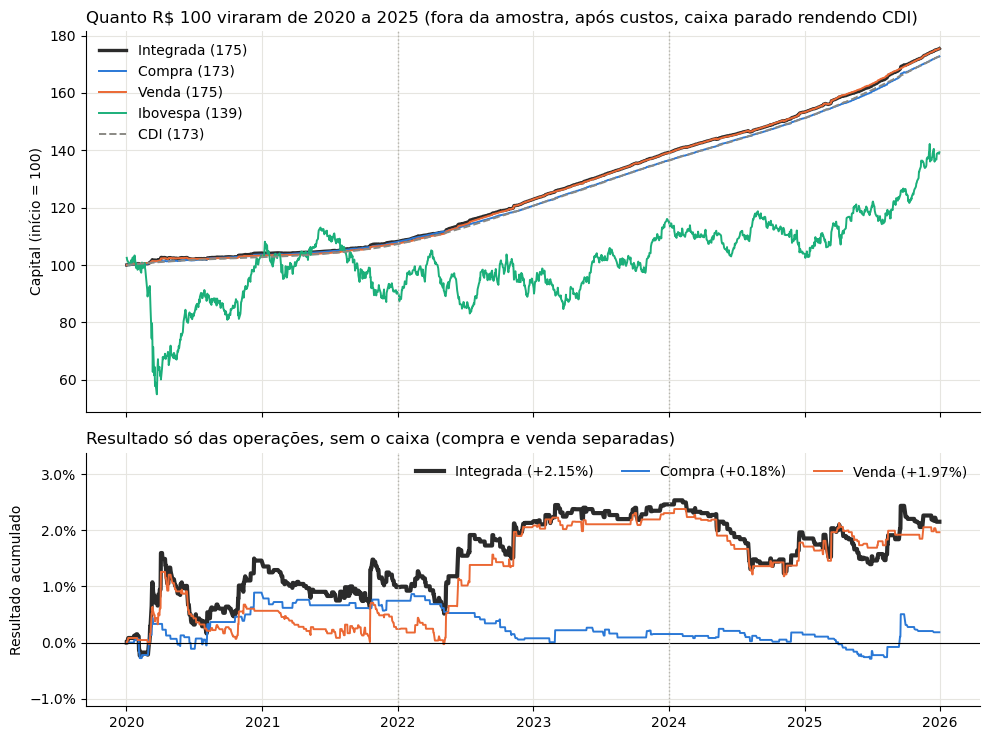

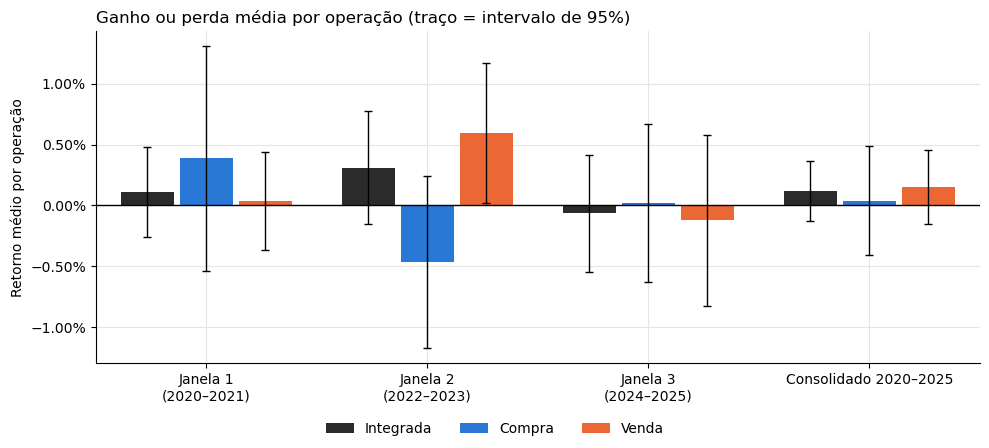

In [15]:
# =============================================================================
# BLOCO 13 — Gráficos
# =============================================================================
from matplotlib.ticker import PercentFormatter

pasta_graficos = PASTA_RESULTADOS / "graficos"
pasta_graficos.mkdir(parents=True, exist_ok=True)
cores = {"Integrada": "#2b2b2b", "Compra": "#2a78d6", "Venda": "#eb6834",
         "Ibovespa": "#1baf7a", "CDI": "#8a8984"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "axes.axisbelow": True, "grid.color": "#e6e5e0", "legend.frameon": False})

# Carteiras sem nenhuma operação no teste (pode acontecer com a regra da validação [D43])
sem_operacoes = [c for c in CARTEIRAS if operacoes_da_carteira(operacoes_teste, c).empty]


# ---- 1. Em cima: curva de capital × Ibovespa × CDI. Embaixo: só as operações --------------
# Com o caixa no CDI, as curvas de compra, venda e integrada ficam quase iguais à do CDI,
# porque quase todo o capital fica no caixa. Por isso compra e venda aparecem no painel
# de baixo, que mostra só o que as operações renderam, sem o caixa.
figura, (eixo, eixo_ops) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, height_ratios=[3, 2])

curvas = {carteira.capitalize(): (1 + retornos_diarios[carteira]).cumprod() for carteira in CARTEIRAS}
curvas.update({"Ibovespa": (1 + ibovespa_diario).cumprod(), "CDI": (1 + cdi_diario).cumprod()})
for nome, curva in curvas.items():
    aviso = ", não operou" if nome.lower() in sem_operacoes else ""
    eixo.plot(100 * curva, color=cores[nome], label=f"{nome} ({100 * curva.iloc[-1]:.0f}{aviso})",
              linewidth=2.4 if nome == "Integrada" else 1.4, linestyle="--" if nome == "CDI" else "-")
caixa = ", caixa parado rendendo CDI" if REMUNERAR_CAIXA_CDI else ""
eixo.set_title(f"Quanto R$ 100 viraram de 2020 a 2025 (fora da amostra, após custos{caixa})", loc="left")
eixo.set_ylabel("Capital (início = 100)")
eixo.legend(loc="upper left")

for carteira in CARTEIRAS:
    so_operacoes = carteira_diaria(operacoes_da_carteira(operacoes_teste, carteira), incluir_caixa=False)
    resultado = (1 + so_operacoes).cumprod() - 1
    rotulo = "não operou" if carteira in sem_operacoes else f"{resultado.iloc[-1]:+.2%}"
    eixo_ops.plot(resultado, color=cores[carteira.capitalize()], label=f"{carteira.capitalize()} ({rotulo})",
                  linewidth=3 if carteira == "integrada" else 1.4)
eixo_ops.axhline(0, color="black", linewidth=0.8)
eixo_ops.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
eixo_ops.set_title("Resultado só das operações, sem o caixa (compra e venda separadas)", loc="left")
eixo_ops.set_ylabel("Resultado acumulado")
eixo_ops.margins(y=0.3)                                         # espaço livre para a legenda
eixo_ops.legend(loc="best", ncols=len(CARTEIRAS))

for e in (eixo, eixo_ops):
    for inicio in JANELAS["teste_inicio"].iloc[1:]:             # separa as janelas de teste
        e.axvline(inicio, color="#b5b4ad", linestyle=":", linewidth=1)
figura.tight_layout()
figura.savefig(pasta_graficos / "1_curva_de_capital.png", dpi=200)
plt.show()


# ---- 2. Retorno médio por operação em cada janela, com intervalo de confiança -------------
figura, eixo = plt.subplots(figsize=(10, 4.5))
nomes_periodos = list(periodos)                                  # 3 janelas + consolidado
largura = 0.8 / len(CARTEIRAS)
for numero, carteira in enumerate(CARTEIRAS):
    tabela = tabela_teste_t.loc[carteira].reindex(nomes_periodos)
    posicoes = np.arange(len(nomes_periodos)) + (numero - (len(CARTEIRAS) - 1) / 2) * largura
    cor = cores[carteira.capitalize()]
    eixo.bar(posicoes, tabela["media"], width=largura * 0.9, color=cor, label=carteira.capitalize())
    traco = [tabela["media"] - tabela["ic_inferior"], tabela["ic_superior"] - tabela["media"]]
    eixo.errorbar(posicoes, tabela["media"], yerr=traco,          # intervalo do teste t (Bloco 11)
                  fmt="none", ecolor="black", elinewidth=1, capsize=3)
    for posicao, media in zip(posicoes, tabela["media"]):
        if pd.isna(media):                                       # sem operações neste período [D43]
            eixo.text(posicao, 0, " não operou", rotation=90, ha="center", va="bottom",
                      fontsize=8, color=cor)
eixo.axhline(0, color="black", linewidth=1)
eixo.set_xlim(-0.5, len(nomes_periodos) - 0.5)                  # mostra as janelas mesmo sem barras
eixo.set_xticks(range(len(nomes_periodos)), [p.replace(" (", "\n(") for p in nomes_periodos])
eixo.yaxis.set_major_formatter(PercentFormatter(1, decimals=2))
eixo.set_ylabel("Retorno médio por operação")
eixo.set_title(f"Ganho ou perda média por operação (traço = intervalo de {NIVEL_CONFIANCA:.0%})", loc="left")
figura.legend(loc="lower center", ncols=len(CARTEIRAS))         # embaixo, fora das barras
figura.tight_layout(rect=(0, 0.06, 1, 1))
figura.savefig(pasta_graficos / "2_retorno_por_janela.png", dpi=200)
plt.show()

## Bloco 14 — Exportação

Conferência dos resultados e download dos arquivos.


In [16]:
# =============================================================================
# BLOCO 14 — Checagens finais e exportação dos resultados
# =============================================================================
import json
import zipfile

# ---- 1. Checagem: os indicadores só usam o passado ------------------------------------
# Sorteia 200 dias e refaz a MM200(t−1) e o corpo relativo de t−1 usando SÓ as
# linhas da mesma ação com data anterior a t.
amostra = base[base["mm200_anterior"].notna()].sample(200, random_state=SEMENTE)
for _, linha in amostra.iterrows():
    passado = base[(base["ativo"] == linha["ativo"]) & (base["data"] < linha["data"])]
    ontem = passado.iloc[-1]
    amplitude_ontem = ontem["maxima"] - ontem["minima"]
    corpo_ontem = abs(ontem["fechamento"] - ontem["abertura"]) / amplitude_ontem if amplitude_ontem > 0 else np.nan
    assert np.isclose(passado["fechamento"].tail(PERIODO_MM).mean(), linha["mm200_anterior"])
    assert np.isclose(corpo_ontem, linha["corpo_relativo_anterior"], equal_nan=True)
    # [D45] o centavo ajustado só usa o próprio dia e os 119 pregões anteriores
    ate_hoje = base[(base["ativo"] == linha["ativo"]) & (base["data"] <= linha["data"])]
    centavo = ate_hoje["menor_distancia"].tail(PREGOES_PARA_ESTIMAR_CENTAVO).min()
    assert np.isclose(centavo, linha["centavo_ajustado"], equal_nan=True)
print("1. Indicadores (MM200, pavio e preço real estimado) recalculados só com o passado "
      "em 200 dias sorteados: OK")

# ---- 2. Checagem: seleção e parâmetros não dependem do futuro ---------------------------
# Apaga temporariamente todos os dados posteriores ao treino (ou à validação) e
# refaz as escolhas. Se o resultado for o mesmo, nenhuma escolha usou o futuro.
base_completa = base
try:
    for janela, datas in JANELAS.iterrows():
        base = base_completa[base_completa["data"] <= datas["treino_fim"]]
        acoes_sem_futuro = selecionar_acoes(datas["treino_inicio"], datas["treino_fim"])[0]
        assert list(acoes_sem_futuro.index) == acoes_por_janela[janela], f"Seleção da janela {janela}"

        base = base_completa[base_completa["data"] <= datas["validacao_fim"]]
        for versao in VERSOES:
            candidatas = otimizar_no_treino(janela, versao)[1]
            assert list(candidatas["id_combinacao"]) == list(candidatas_treino[(janela, versao)]["id_combinacao"])
            escolha = escolher_na_validacao(janela, versao)[0]
            agora = None if escolha is None else escolha["id_combinacao"]
            assert agora == parametros_escolhidos["id_combinacao"].get((janela, versao))
finally:
    base = base_completa                       # devolve a base completa, aconteça o que acontecer
print("2. Seleção de ações e escolha de parâmetros refeitas sem os dados futuros: iguais. OK")
print("3. Exemplos à mão (Bloco 4), conferência com o QuantBrasil (Bloco 5) e testes sem "
      "sobreposição (Bloco 9) já foram verificados nos seus blocos.")


# ---- 3. Resumo para a apresentação --------------------------------------------------------
# Junta numa tabela só as métricas principais (consolidado 2020–2025), por janela e de robustez.
consolidado = "Consolidado 2020–2025"
resumo_consolidado = tabela_metricas.xs(consolidado, level="periodo").copy()
resumo_consolidado["p_valor"] = tabela_teste_t.xs(consolidado, level="periodo")["p_valor"]
resumo_consolidado["ic_95_sharpe"] = tabela_bootstrap.xs(consolidado, level="periodo")["ic_em_blocos"]
resumo_consolidado = resumo_consolidado[[
    "operacoes", "exposicao_media", "taxa_acerto", "payoff", "retorno_medio_liquido", "p_valor",
    "retorno_acumulado", "retorno_anualizado", "volatilidade_anualizada", coluna_sharpe, "ic_95_sharpe",
    "drawdown_maximo"]]

resumo_por_janela = tabela_metricas.loc[list(CARTEIRAS), ["operacoes", "retorno_medio_liquido",
                                                          "taxa_acerto", "retorno_acumulado",
                                                          coluna_sharpe, "drawdown_maximo"]].copy()
resumo_por_janela["p_valor"] = tabela_teste_t["p_valor"]

resumo_robustez = analises[["operacoes", "retorno_medio_liquido", "p_valor", "retorno_acumulado"]]

formatos_resumo = {"operacoes": "{:.0f}", "exposicao_media": "{:.2%}", "taxa_acerto": "{:.1%}",
                   "payoff": "{:.2f}", "retorno_medio_liquido": "{:+.3%}", "p_valor": "{:.3f}",
                   "retorno_acumulado": "{:+.2%}", "retorno_anualizado": "{:+.2%}",
                   "volatilidade_anualizada": "{:.2%}", "sharpe_sem_cdi": "{:+.2f}",
                   "sharpe_com_cdi": "{:+.2f}", "drawdown_maximo": "{:+.2%}"}

def imprimir(titulo, tabela):
    """Imprime uma tabela do resumo com os números formatados (vazio aparece como –)."""
    texto = tabela.astype(object)
    for coluna, formato in formatos_resumo.items():
        if coluna in texto.columns:
            texto[coluna] = ["–" if pd.isna(v) else formato.format(v) for v in tabela[coluna]]
    print(f"\n{titulo}")
    print(texto.fillna("–").to_string())


# ---- 4. Exportação: um Excel com todas as tabelas + a configuração usada ----------------
def empilhar(dicionario, nomes_das_chaves):
    """Junta as tabelas de um dicionário {chave: tabela} numa só, com a chave virando coluna."""
    return pd.concat(dicionario, names=nomes_das_chaves).reset_index(level=nomes_das_chaves)

abas = {
    "resumo_consolidado": resumo_consolidado.reset_index(),
    "resumo_por_janela": resumo_por_janela.reset_index(),
    "resumo_robustez": resumo_robustez.reset_index(),
    "configuracao": pd.DataFrame({"parametro": list(CONFIGURACAO_USADA),
                                  "valor": [str(v) for v in CONFIGURACAO_USADA.values()]}),
    "grade_36_combinacoes": GRADE,
    "janelas": JANELAS.reset_index(),
    "qualidade_dos_dados": pd.DataFrame(relatorio, columns=["etapa", "linhas", "ativos"]),
    "gaps_de_evento": gaps_de_evento,
    "funil_selecao": pd.DataFrame(funis).rename_axis("etapa").reset_index(),
    "acoes_por_janela": empilhar(selecao_por_janela, ["janela"]).reset_index(),
    "superficie_treino": empilhar(superficies_treino, ["janela", "versao"]),
    "treino_vs_validacao": empilhar(treino_vs_validacao, ["janela", "versao"]),
    "parametros_escolhidos": parametros_escolhidos.reset_index(),
    "operacoes_teste": operacoes_teste,
    "retornos_diarios": retornos_diarios.assign(ibovespa=ibovespa_diario, cdi=cdi_diario)
                                        .rename_axis("data").reset_index(),
    "metricas": tabela_metricas.reset_index(),
    "teste_t": tabela_teste_t.reset_index(),
    "bootstrap_sharpe": tabela_bootstrap.reset_index(),
    "analises_complementares": analises.reset_index(),
}

arquivo_excel = PASTA_RESULTADOS / "resultados_candle_pavio.xlsx"
with pd.ExcelWriter(arquivo_excel) as escritor:
    for nome_aba, tabela in abas.items():
        tabela.to_excel(escritor, sheet_name=nome_aba, index=False)

arquivo_configuracao = PASTA_RESULTADOS / "configuracao_usada.json"
with open(arquivo_configuracao, "w", encoding="utf-8") as arquivo:
    json.dump(CONFIGURACAO_USADA, arquivo, ensure_ascii=False, indent=2, default=str)

# Junta Excel, configuração, cópia do CDI e gráficos num .zip (a cópia dos Excels fica de fora)
arquivo_zip = PASTA_RESULTADOS / "resultados_candle_pavio.zip"
with zipfile.ZipFile(arquivo_zip, "w") as zip_saida:
    for arquivo in [arquivo_excel, arquivo_configuracao, ARQUIVO_CDI, *sorted(pasta_graficos.glob("*.png"))]:
        zip_saida.write(arquivo, arquivo.relative_to(PASTA_RESULTADOS))

print(f"\nExcel com {len(abas)} abas: {arquivo_excel.name} (as 3 primeiras são o resumo)")
print(f"Pacote para baixar: {arquivo_zip} ({arquivo_zip.stat().st_size / 1e6:.1f} MB)")


# ---- 5. Resumo na tela ---------------------------------------------------------------------
print("\n" + "=" * 100)
print("RESUMO PARA A APRESENTAÇÃO — fora da amostra (2020–2025), após custos de "
      f"{CUSTO_IDA_E_VOLTA:.2%} por operação | integrada = compra + venda na mesma carteira")
print(f"Caixa parado rende CDI: {REMUNERAR_CAIXA_CDI} | só opera o que foi positivo na validação: "
      f"{EXIGIR_RETORNO_POSITIVO_VALIDACAO} | Sharpe mostrado: {coluna_sharpe}")
print("=" * 100)
imprimir("1) Consolidado 2020–2025:", resumo_consolidado)
imprimir("2) Por janela de teste (carteiras da estratégia):", resumo_por_janela)
imprimir("3) Robustez (mesmas ações e parâmetros, mudando uma regra):", resumo_robustez)
print("\n4) Parâmetros escolhidos em cada janela:")
print(parametros_escolhidos[["theta", "gap_minimo", "stop"]].to_string(formatters={
    "theta": "{:.0%}".format, "gap_minimo": "{:.1%}".format, "stop": "{:.0%}".format}))
nao_operaram = [f"janela {j} ({v})" for j in JANELAS.index for v in VERSOES
                if (j, v) not in parametros_escolhidos.index]
print("   Não operaram (capital no CDI):", ", ".join(nao_operaram) if nao_operaram else "nenhuma")
print(f"\n5) Ações por janela: {', '.join(f'janela {j} = {len(a)}' for j, a in acoes_por_janela.items())}"
      f" | K = {K_FIXO} | {len(GRADE)} combinações testadas por versão (múltiplos testes)")

# Os resultados são salvos na pasta local, com download opcional no Colab.
print(f"\nPasta de resultados: {PASTA_RESULTADOS.resolve()}")
if EM_COLAB:
    from google.colab import files
    files.download(str(arquivo_zip))

1. Indicadores (MM200, pavio e preço real estimado) recalculados só com o passado em 200 dias sorteados: OK
2. Seleção de ações e escolha de parâmetros refeitas sem os dados futuros: iguais. OK
3. Exemplos à mão (Bloco 4), conferência com o QuantBrasil (Bloco 5) e testes sem sobreposição (Bloco 9) já foram verificados nos seus blocos.

Excel com 19 abas: resultados_candle_pavio.xlsx (as 3 primeiras são o resumo)
Pacote para baixar: /Users/carolinayumigentil/Documents/GitHub/projeto-avantgarde-2/c-digos---projeto-final-/grupo 1/resultados/candle_pavio_final/resultados_candle_pavio.zip (0.6 MB)

RESUMO PARA A APRESENTAÇÃO — fora da amostra (2020–2025), após custos de 0.10% por operação | integrada = compra + venda na mesma carteira
Caixa parado rende CDI: True | só opera o que foi positivo na validação: False | Sharpe mostrado: sharpe_com_cdi

1) Consolidado 2020–2025:
          operacoes exposicao_media taxa_acerto payoff retorno_medio_liquido p_valor retorno_acumulado retorno_anualizad

## Bloco 15 — Indicadores do relatório

Tabelas com as métricas finais da estratégia.


In [17]:
# =============================================================================
# BLOCO 15 — Números do paper
# =============================================================================
# Junta, em tabelas prontas para o texto, as medidas do paper de referência (CAGR,
# volatilidade, Sharpe, beta, alfa, VaR, drawdown, ações mais frequentes) e outras
# específicas da nossa estratégia. Nada aqui escolhe ações ou parâmetros: só descreve
# o teste (2020–2025) dos Blocos 9 a 12, além de um fato de 2015–2019 (seção 7).
import zipfile

def mostrar(titulo, tabela, formatos):
    """Imprime uma tabela com os números formatados (vazio aparece como –)."""
    print(f"\n{titulo}")
    print(tabela.to_string(na_rep="–", formatters={c: f.format for c, f in formatos.items()
                                                   if c in tabela.columns}))

PCT, PCT3, NUM = "{:+.2%}", "{:+.3%}", "{:+.2f}"     # formatos usados nas tabelas abaixo
periodo_todo = "Consolidado 2020–2025"
carteiras_que_operaram = [c for c in CARTEIRAS if not operacoes_da_carteira(operacoes_teste, c).empty]
print(f"NÚMEROS DO PAPER — versão {VERSAO} | teste 2020–2025 | carteiras que operaram: {carteiras_que_operaram}")


# ---- 1. Indicadores da carteira (os do paper de referência) ---------------------------
def beta_e_alfa(retornos):
    """Regressão do excesso sobre o CDI da carteira contra o excesso do Ibovespa (CAPM):
        excesso_carteira = alfa + beta × excesso_ibovespa + erro
    Erros-padrão de Newey-West, que aceitam dias seguidos parecidos [D48].
    Retorna (beta, alfa ao ano, estatística t do alfa)."""
    excesso_carteira = retornos - cdi_diario
    excesso_ibovespa = sm.add_constant(ibovespa_diario - cdi_diario)
    modelo = sm.OLS(excesso_carteira, excesso_ibovespa).fit(
        cov_type="HAC", cov_kwds={"maxlags": DEFASAGENS_NEWEY_WEST})
    return modelo.params.iloc[1], modelo.params.iloc[0] * PREGOES_POR_ANO, modelo.tvalues.iloc[0]


cagr_do_cdi = tabela_metricas.loc[("CDI", periodo_todo), "retorno_anualizado"]
linhas_indicadores = []
for nome, retornos in series.items():                       # carteiras, Ibovespa e CDI (Bloco 10)
    metricas = tabela_metricas.loc[(nome, periodo_todo)]
    pior_5_porcento = retornos.quantile(1 - NIVEL_CONFIANCA)  # o dia que separa os 5% piores
    linha = pd.Series({
        "cagr": metricas["retorno_anualizado"],
        "cagr_acima_do_cdi": metricas["retorno_anualizado"] - cagr_do_cdi,
        "volatilidade": metricas["volatilidade_anualizada"],
        "sharpe": metricas[coluna_sharpe],                  # o mesmo dos Blocos 12 e 14
        "drawdown_maximo": metricas["drawdown_maximo"],
        "var_95_diario": -pior_5_porcento,                  # perda que só é superada em 5% dos dias
        "cvar_95_diario": -retornos[retornos <= pior_5_porcento].mean(),   # perda média nesses 5%
    }, name=nome)
    if nome in carteiras_que_operaram:                       # beta e alfa só para quem operou
        linha["beta"], linha["alfa_ao_ano"], linha["t_do_alfa"] = beta_e_alfa(retornos)
        linha["correlacao_ibovespa"] = retornos.corr(ibovespa_diario)
    linhas_indicadores.append(linha)
indicadores = pd.DataFrame(linhas_indicadores)

mostrar(f"1) Indicadores da carteira, {periodo_todo} (Sharpe = {coluna_sharpe}):", indicadores,
        {"cagr": PCT, "cagr_acima_do_cdi": PCT, "volatilidade": "{:.2%}", "sharpe": NUM,
         "drawdown_maximo": PCT, "var_95_diario": PCT3, "cvar_95_diario": PCT3, "beta": NUM,
         "alfa_ao_ano": PCT, "t_do_alfa": NUM, "correlacao_ibovespa": NUM})
print("   VaR e CVaR: perda que só é superada em 5% dos dias, e a perda média nesses dias. Valor negativo "
      "= mesmo nesses dias a carteira ganhou (o caixa rende CDI).")
print("   Tracking error e information ratio contra o Ibovespa ficam de fora: a estratégia não tenta "
      "acompanhar o índice (beta perto de zero), então eles só repetiriam a volatilidade do Ibovespa.")
if not REMUNERAR_CAIXA_CDI:
    print("   Atenção: nesta versão o caixa parado rende 0%, então o alfa sobre o CDI inclui todo o CDI "
          "que o capital parado deixou de ganhar.")


# ---- 2. Como a estratégia ganha ou perde (por operação) --------------------------------
def decompor_operacoes(ops):
    """Acerto, ganho e perda médios, expectativa e o papel do stop."""
    liquido = ops["retorno_liquido"]
    stopadas = ops["stop_acionado"].astype(bool)
    acerto = (liquido > 0).mean()
    ganho_medio = liquido[liquido > 0].mean()
    perda_media = -liquido[liquido <= 0].mean()
    return pd.Series({
        "operacoes": len(ops),
        "taxa_acerto": acerto,
        "ganho_medio": ganho_medio,
        "perda_media": perda_media,
        # Expectativa = acerto × ganho médio − erro × perda média (é o retorno médio por operação)
        "expectativa": acerto * ganho_medio - (1 - acerto) * perda_media,
        "fracao_stopadas": stopadas.mean(),
        "media_das_stopadas": liquido[stopadas].mean(),
        "media_das_nao_stopadas": liquido[~stopadas].mean(),
        "var_95_por_operacao": -liquido.quantile(1 - NIVEL_CONFIANCA),
        "pior_operacao": liquido.min(),
    })

por_operacao = pd.DataFrame({c: decompor_operacoes(operacoes_da_carteira(operacoes_teste, c))
                             for c in carteiras_que_operaram}).T
for carteira in carteiras_que_operaram:                      # confere a conta da expectativa
    media = operacoes_da_carteira(operacoes_teste, carteira)["retorno_liquido"].mean()
    assert np.isclose(por_operacao.loc[carteira, "expectativa"], media)

mostrar("2) Como a estratégia ganha ou perde, por operação (expectativa = retorno médio):", por_operacao,
        {"operacoes": "{:.0f}", "taxa_acerto": "{:.1%}", "ganho_medio": PCT, "perda_media": "{:.2%}",
         "expectativa": PCT3, "fracao_stopadas": "{:.1%}", "media_das_stopadas": PCT,
         "media_das_nao_stopadas": PCT, "var_95_por_operacao": PCT, "pior_operacao": PCT})


# ---- 3. Resultado por ano ---------------------------------------------------------------
linhas_ano = []
for carteira in carteiras_que_operaram:
    ops = operacoes_da_carteira(operacoes_teste, carteira)
    for ano, ops_ano in ops.groupby(ops["data"].dt.year):
        dias_do_ano = retornos_diarios.index.year == ano
        linhas_ano.append({
            "carteira": carteira, "ano": ano, "operacoes": len(ops_ano),
            "retorno_medio": ops_ano["retorno_liquido"].mean(),
            "taxa_acerto": (ops_ano["retorno_liquido"] > 0).mean(),
            "carteira_no_ano": (1 + retornos_diarios.loc[dias_do_ano, carteira]).prod() - 1,
            "cdi_no_ano": (1 + cdi_diario[dias_do_ano]).prod() - 1,
        })
por_ano = pd.DataFrame(linhas_ano).set_index(["carteira", "ano"])
mostrar("3) Resultado por ano (só anos com operação):", por_ano,
        {"operacoes": "{:.0f}", "retorno_medio": PCT3, "taxa_acerto": "{:.1%}",
         "carteira_no_ano": PCT, "cdi_no_ano": PCT})


# ---- 4. Ações que mais operaram (como a Tabela 2 do paper de referência) ----------------
# Contribuição = soma de (retorno da operação × 1/K): quanto cada ação somou ao capital.
peso_da_operacao = 1 / operacoes_teste["janela"].map(k_da_janela)
por_acao = (operacoes_teste.assign(contribuicao=operacoes_teste["retorno_liquido"] * peso_da_operacao)
            .groupby("ativo").agg(operacoes=("retorno_liquido", "size"),
                                  retorno_medio=("retorno_liquido", "mean"),
                                  taxa_acerto=("retorno_liquido", lambda r: (r > 0).mean()),
                                  contribuicao=("contribuicao", "sum")))
por_acao.insert(1, "fracao_das_operacoes", por_acao["operacoes"] / len(operacoes_teste))
marcadas_rj_opa = {acao for lista in acoes_rj_opa.values() for acao in lista}   # Bloco 12
por_acao["rj_ou_opa"] = np.where(por_acao.index.isin(marcadas_rj_opa), "sim", "")
por_acao = por_acao.sort_values(["operacoes", "contribuicao"], ascending=False)
mostrar(f"4) As 10 ações que mais operaram (de {len(por_acao)}; contribuição em % do capital):",
        por_acao.head(10), {"operacoes": "{:.0f}", "fracao_das_operacoes": "{:.1%}",
                            "retorno_medio": PCT3, "taxa_acerto": "{:.1%}", "contribuicao": PCT})


# ---- 5. Treino → validação → teste (o quanto o resultado cai fora da amostra) -----------
linhas_etapas = []
for (janela, versao), parametros in parametros_escolhidos.iterrows():
    lado_a_lado = treino_vs_validacao[(janela, versao)]                       # Bloco 8
    escolhida = lado_a_lado[lado_a_lado["id_combinacao"] == parametros["id_combinacao"]].iloc[0]
    ops = operacoes_teste[(operacoes_teste["janela"] == janela) & (operacoes_teste["versao"] == versao)]
    linhas_etapas.append({
        "janela": janela, "versao": versao,
        "operacoes_treino": escolhida["operacoes_treino"],
        "retorno_treino": escolhida["retorno_medio_liquido_treino"],
        "operacoes_validacao": escolhida["operacoes_validacao"],
        "retorno_validacao": escolhida["retorno_medio_liquido_validacao"],
        "operacoes_teste": len(ops),
        "retorno_teste": ops["retorno_liquido"].mean(),
    })
etapas = pd.DataFrame(linhas_etapas).set_index(["janela", "versao"])
mostrar("5) Retorno médio por operação da combinação escolhida em cada etapa:", etapas,
        {"operacoes_treino": "{:.0f}", "operacoes_validacao": "{:.0f}", "operacoes_teste": "{:.0f}",
         "retorno_treino": PCT3, "retorno_validacao": PCT3, "retorno_teste": PCT3})


# ---- 6. O que cada regra acrescenta (funil das regras, no teste) ------------------------
# Mesmas ações e parâmetros, ligando as regras uma de cada vez (função do Bloco 9).
# A pergunta central da pesquisa é a linha 2: o Candle Pavio melhora o resultado do gap?
etapas_do_funil = {
    "1. Só o gap a favor": rodar_teste(filtro_tendencia=False, exigir_pavio=False),
    "2. + Candle Pavio na véspera": rodar_teste(filtro_tendencia=False),
    "3. + filtro da MM200 (estratégia)": operacoes_teste,
}
linhas_funil = []
for etapa, ops_etapa in etapas_do_funil.items():
    for carteira in carteiras_que_operaram:
        teste = teste_t_agrupado(operacoes_da_carteira(ops_etapa, carteira))   # Bloco 11
        linhas_funil.append({"etapa": etapa, "carteira": carteira, "operacoes": teste["operacoes"],
                             "retorno_medio": teste["media"], "p_valor": teste["p_valor"]})
funil_das_regras = pd.DataFrame(linhas_funil).set_index(["etapa", "carteira"])
mostrar("6) O que cada regra acrescenta (teste 2020–2025):", funil_das_regras,
        {"operacoes": "{:.0f}", "retorno_medio": PCT3, "p_valor": "{:.3f}"})


# ---- 7. Fato de 2015–2019: o que acontece no dia depois de um gap ----------------------
# Usa SÓ dados anteriores a todos os testes, com as ações da janela 1. Para cada faixa de
# gap, o retorno da abertura ao fechamento (bruto, sem custo e sem stop) e o teste t do
# Bloco 11. Se o preço tende a VOLTAR depois do gap, comprar o gap de alta perde dinheiro.
antes_do_teste = base[(base["data"] < JANELAS["teste_inicio"].min())
                      & base["ativo"].isin(acoes_por_janela[1]) & base["gap"].notna()]
dias_com_gap = pd.DataFrame({
    "data": antes_do_teste["data"],
    "faixa_de_gap": pd.cut(antes_do_teste["gap"], FAIXAS_DE_GAP),
    "retorno_liquido": antes_do_teste["fechamento"] / antes_do_teste["abertura"] - 1,   # aqui, bruto
})
gaps_2015_2019 = pd.DataFrame({faixa: teste_t_agrupado(grupo)
                               for faixa, grupo in dias_com_gap.groupby("faixa_de_gap", observed=True)}).T


def nome_da_faixa(faixa):
    """Texto da faixa de gap: as das pontas viram 'abaixo de' e 'acima de'."""
    if faixa.left == FAIXAS_DE_GAP[0]:
        return f"gap abaixo de {faixa.right:+.1%}"
    if faixa.right == FAIXAS_DE_GAP[-1]:
        return f"gap acima de {faixa.left:+.1%}"
    return f"gap de {faixa.left:+.1%} a {faixa.right:+.1%}"

gaps_2015_2019.index = [nome_da_faixa(f) for f in gaps_2015_2019.index]
mostrar("7) 2015–2019: retorno da abertura ao fechamento, por faixa de gap (ações da janela 1):",
        gaps_2015_2019[["operacoes", "media", "t", "p_valor"]].rename(columns={"operacoes": "dias"}),
        {"dias": "{:.0f}", "media": PCT3, "t": NUM, "p_valor": "{:.3f}"})


# ---- 8. Exportação ------------------------------------------------------------------------
abas_do_paper = {
    "1_indicadores": indicadores.rename_axis("serie"),
    "2_por_operacao": por_operacao.rename_axis("carteira"),
    "3_por_ano": por_ano,
    "4_por_acao": por_acao,
    "5_treino_validacao_teste": etapas,
    "6_funil_das_regras": funil_das_regras,
    "7_gaps_2015_2019": gaps_2015_2019.rename_axis("faixa"),
}
arquivo_paper = PASTA_RESULTADOS / "numeros_do_paper.xlsx"
with pd.ExcelWriter(arquivo_paper) as escritor:
    for nome_aba, tabela in abas_do_paper.items():
        tabela.reset_index().to_excel(escritor, sheet_name=nome_aba, index=False)
with zipfile.ZipFile(arquivo_zip, "a") as zip_saida:          # junta ao .zip do Bloco 14
    if arquivo_paper.name not in zip_saida.namelist():
        zip_saida.write(arquivo_paper, arquivo_paper.name)
print(f"\nExcel com {len(abas_do_paper)} abas: {arquivo_paper.name} (também colocado no .zip)")

print(f"\nRESULTADOS CONCLUÍDOS — pasta: {PASTA_RESULTADOS.resolve()}")
print(f"Planilhas: {arquivo_excel.name}, {arquivo_paper.name}")
print(f"Gráficos: {pasta_graficos.resolve()}")
print(f"Arquivo ZIP: {arquivo_zip.resolve()}")
if EM_COLAB:
    from google.colab import files
    files.download(str(arquivo_paper))

NÚMEROS DO PAPER — versão 3 | teste 2020–2025 | carteiras que operaram: ['integrada', 'compra', 'venda']

1) Indicadores da carteira, Consolidado 2020–2025 (Sharpe = sharpe_com_cdi):
            cagr cagr_acima_do_cdi volatilidade sharpe drawdown_maximo var_95_diario cvar_95_diario  beta alfa_ao_ano t_do_alfa correlacao_ibovespa
integrada +9.83%            +0.28%        0.97%  +0.28          -0.61%       +0.029%        +0.078% -0.00      +0.26%     +0.65               -0.10
compra    +9.55%            +0.00%        0.54%  +0.00          -0.30%       -0.007%        +0.007% +0.00      +0.00%     +0.01               +0.06
venda     +9.83%            +0.28%        0.86%  +0.33          -0.40%       +0.026%        +0.064% -0.01      +0.26%     +0.77               -0.15
Ibovespa  +5.69%            -3.86%       24.34%  -0.03         -46.82%       +2.073%        +3.531%     –           –         –                   –
CDI       +9.55%            +0.00%        0.27%      –          +0.00%       